In [2]:
!unzip -q "Dental X-ray.v1i.yolov8.zip" -d /content/dataset

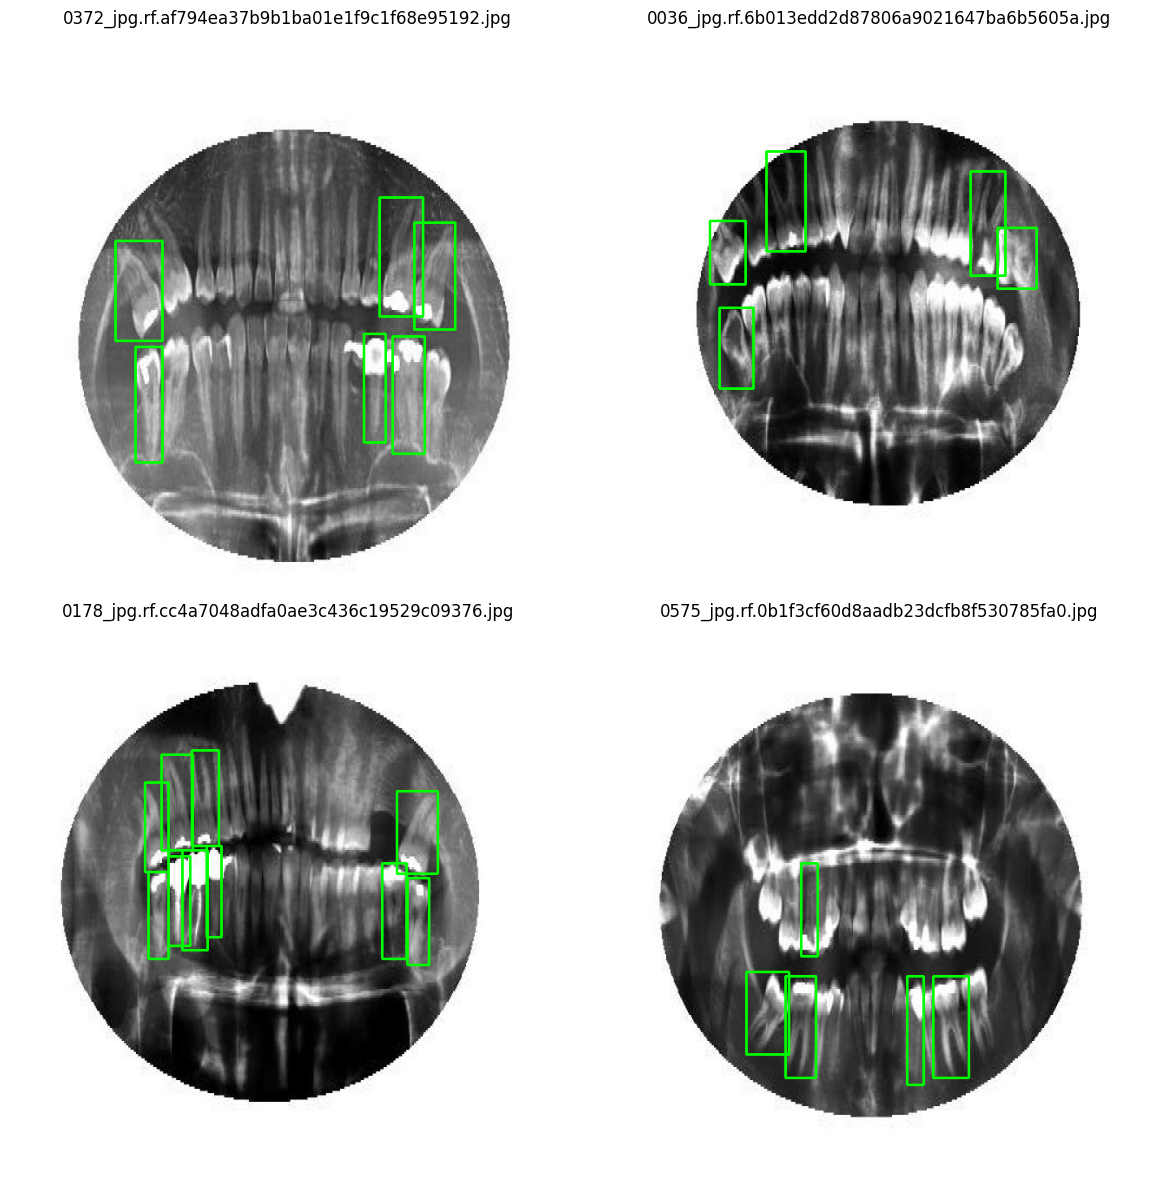

In [3]:
import cv2
import matplotlib.pyplot as plt
import glob
import os

# Get a list of sample images
image_paths = glob.glob('/content/dataset/train/images/*.jpg')[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.ravel()

for idx, img_path in enumerate(image_paths):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Read matching label file
    label_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt')

    if os.path.exists(label_path):
        h, w, _ = img.shape
        with open(label_path, 'r') as f:
            for line in f.readlines():
                class_id, cx, cy, bw, bh = map(float, line.strip().split())
                # Convert normalized YOLO coordinates to pixels
                xmin = int((cx - bw / 2) * w)
                ymin = int((cy - bh / 2) * h)
                xmax = int((cx + bw / 2) * w)
                ymax = int((cy + bh / 2) * h)
                cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)

    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(os.path.basename(img_path))

plt.tight_layout()
plt.show()

In [4]:
import glob
import pandas as pd
import numpy as np

# Load all annotation text files
label_files = glob.glob('/content/dataset/train/labels/*.txt')

records = []
for file in label_files:
    with open(file, 'r') as f:
        for line in f.readlines():
            cls, cx, cy, w, h = map(float, line.strip().split())
            records.append({
                'class_id': int(cls),
                'center_x': cx,
                'center_y': cy,
                'width': w,
                'height': h,
                'area': w * h,
                'aspect_ratio': w / (h + 1e-6)
            })

df = pd.DataFrame(records)

print("--- CLASS DISTRIBUTION ---")
print(df['class_id'].value_counts())

print("\n--- BOX METRICS ---")
print(df[['area', 'width', 'height', 'aspect_ratio']].describe())

--- CLASS DISTRIBUTION ---
class_id
1    3692
3    1225
0     398
2     316
Name: count, dtype: int64

--- BOX METRICS ---
              area        width       height  aspect_ratio
count  5631.000000  5631.000000  5631.000000   5631.000000
mean      0.008480     0.047474     0.176447      0.280900
std       0.003787     0.017133     0.039737      0.118107
min       0.000012     0.001563     0.003906      0.051282
25%       0.005875     0.032813     0.156250      0.192307
50%       0.007819     0.045312     0.175781      0.258620
75%       0.010635     0.058594     0.199219      0.342260
max       0.028564     0.117188     0.304688      1.599591


/tmp/ipykernel_3029/4017541286.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=counts, x='class_name', y='count', palette='viridis')


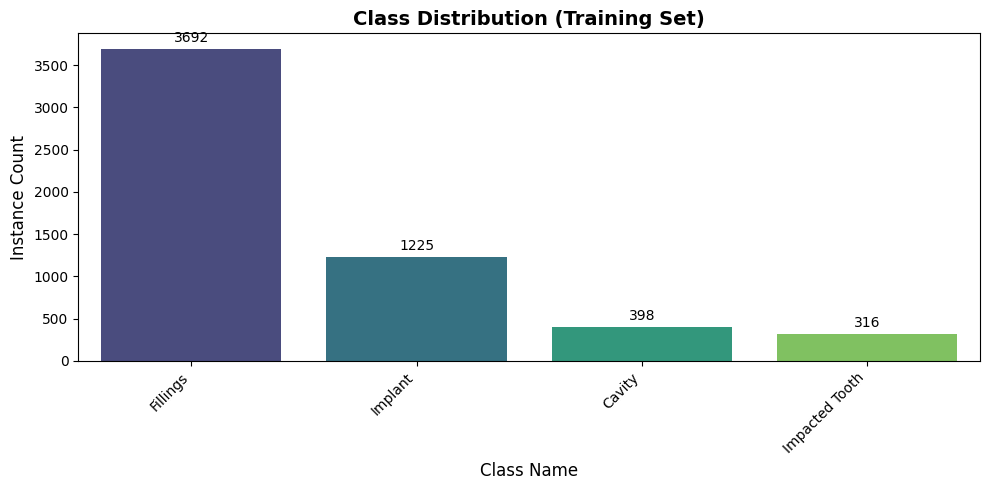

In [5]:
import glob
import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load class names from data.yaml
yaml_path = '/content/dataset/data.yaml'
class_names = {}

if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data_cfg = yaml.safe_load(f)
        names = data_cfg.get('names', {})
        if isinstance(names, list):
            class_names = {i: name for i, name in enumerate(names)}
        elif isinstance(names, dict):
            class_names = {int(k): v for k, v in names.items()}

# 2. Extract class IDs from training label files
label_files = glob.glob('/content/dataset/train/labels/*.txt')

class_ids = []
for file in label_files:
    with open(file, 'r') as f:
        for line in f.readlines():
            parts = line.strip().split()
            if parts:
                class_ids.append(int(parts[0]))

# 3. Build DataFrame and map IDs to names
df = pd.DataFrame({'class_id': class_ids})
df['class_name'] = df['class_id'].map(lambda x: class_names.get(x, f'Class {x}'))

# 4. Plot class counts
counts = df['class_name'].value_counts().reset_index()
counts.columns = ['class_name', 'count']

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=counts, x='class_name', y='count', palette='viridis')

plt.title('Class Distribution (Training Set)', fontsize=14, fontweight='bold')
plt.xlabel('Class Name', fontsize=12)
plt.ylabel('Instance Count', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Display total count above each bar
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

#### First Issue : Class Imbalance

--- DENSITY STATISTICS ---
Total Images analyzed : 753
Total Bounding Boxes  : 5631
Mean Boxes per Image  : 7.48
Median Boxes per Image: 7.0
Min / Max per Image   : 1 / 26
Background Images (0) : 0 (0.0%)


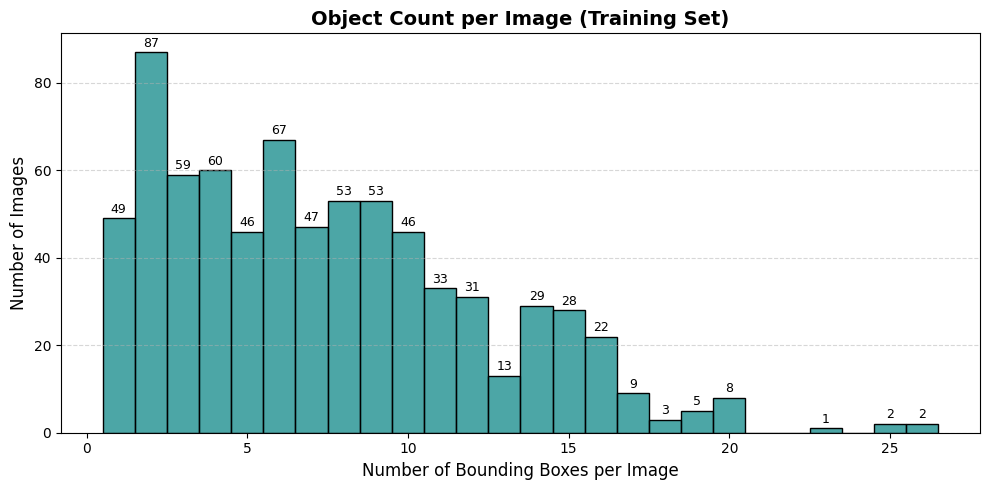

In [6]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Collect all images to account for both annotated and background images
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
image_files = []
for ext in image_extensions:
    image_files.extend(glob.glob(f'/content/dataset/train/images/{ext}'))

# 2. Count bounding boxes per image file
counts = []
for img_path in image_files:
    filename = os.path.basename(img_path)
    basename = os.path.splitext(filename)[0]
    label_path = f'/content/dataset/train/labels/{basename}.txt'

    box_count = 0
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = [line.strip() for line in f.readlines() if line.strip()]
            box_count = len(lines)

    counts.append({'image': filename, 'box_count': box_count})

df = pd.DataFrame(counts)

# 3. Print summary statistics
print("--- DENSITY STATISTICS ---")
print(f"Total Images analyzed : {len(df)}")
print(f"Total Bounding Boxes  : {df['box_count'].sum()}")
print(f"Mean Boxes per Image  : {df['box_count'].mean():.2f}")
print(f"Median Boxes per Image: {df['box_count'].median():.1f}")
print(f"Min / Max per Image   : {df['box_count'].min()} / {df['box_count'].max()}")
print(f"Background Images (0) : {(df['box_count'] == 0).sum()} ({(df['box_count'] == 0).mean()*100:.1f}%)")

# 4. Plot Histogram
plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df, x='box_count', discrete=True, color='teal', edgecolor='black', alpha=0.7)

plt.title('Object Count per Image (Training Set)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Bounding Boxes per Image', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate exact counts over bars
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

#### Second Issue: There is No BackGround image with no detections , that may cause an issue with real usage in deployment

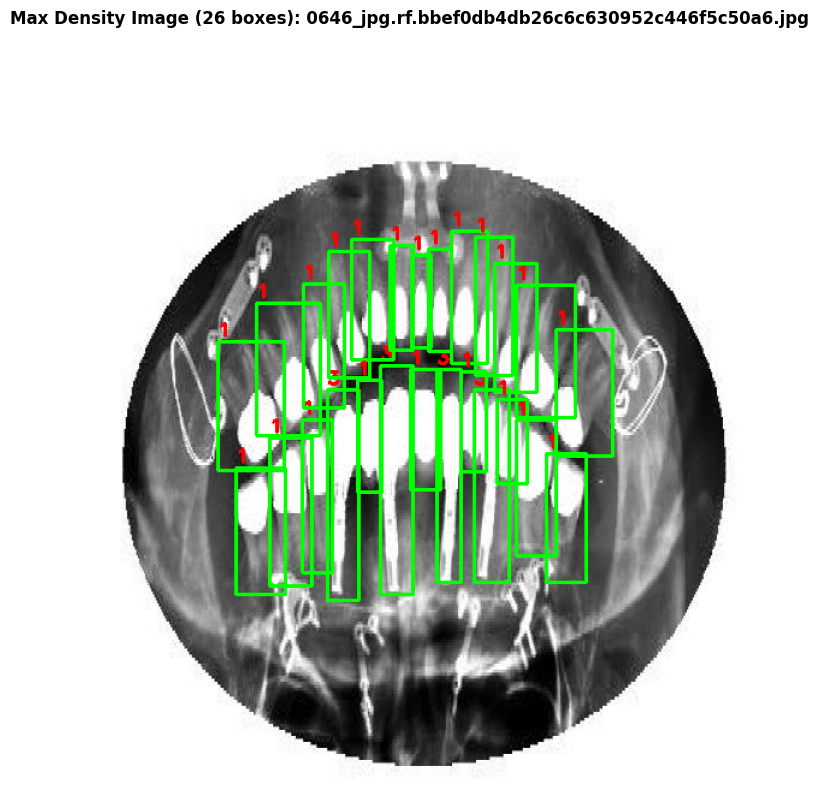

In [7]:
import cv2
import glob
import os
import matplotlib.pyplot as plt

# 1. Locate the image file that has exactly 26 bounding boxes
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
target_img_path = None
target_label_path = None

for ext in image_extensions:
    for img_path in glob.glob(f'/content/dataset/train/images/{ext}'):
        filename = os.path.basename(img_path)
        basename = os.path.splitext(filename)[0]
        label_path = f'/content/dataset/train/labels/{basename}.txt'

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = [line.strip() for line in f.readlines() if line.strip()]
                if len(lines) == 26:
                    target_img_path = img_path
                    target_label_path = label_path
                    break
    if target_img_path:
        break

# 2. Render and plot the image with bounding boxes
if target_img_path:
    img = cv2.imread(target_img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    with open(target_label_path, 'r') as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]
        for line in lines:
            cls, cx, cy, bw, bh = map(float, line.split())
            # Convert normalized coordinates to pixel coordinates
            xmin = int((cx - bw / 2) * w)
            ymin = int((cy - bh / 2) * h)
            xmax = int((cx + bw / 2) * w)
            ymax = int((cy + bh / 2) * h)

            # Draw bounding box and label index
            cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
            cv2.putText(img, str(int(cls)), (xmin, max(ymin - 5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Max Density Image ({len(lines)} boxes): {os.path.basename(target_img_path)}",
              fontsize=12, fontweight='bold')
    plt.show()
else:
    print("Could not find an image with exactly 26 bounding boxes.")

In [8]:
import yaml

# Read and print class names from data.yaml
yaml_path = '/content/dataset/data.yaml'

with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

print("--- DATASET CLASSES ---")
names = data_cfg.get('names', {})
if isinstance(names, list):
    for idx, name in enumerate(names):
        print(f"ID {idx}: {name}")
elif isinstance(names, dict):
    for idx, name in names.items():
        print(f"ID {idx}: {name}")

--- DATASET CLASSES ---
ID 0: Cavity
ID 1: Fillings
ID 2: Impacted Tooth
ID 3: Implant


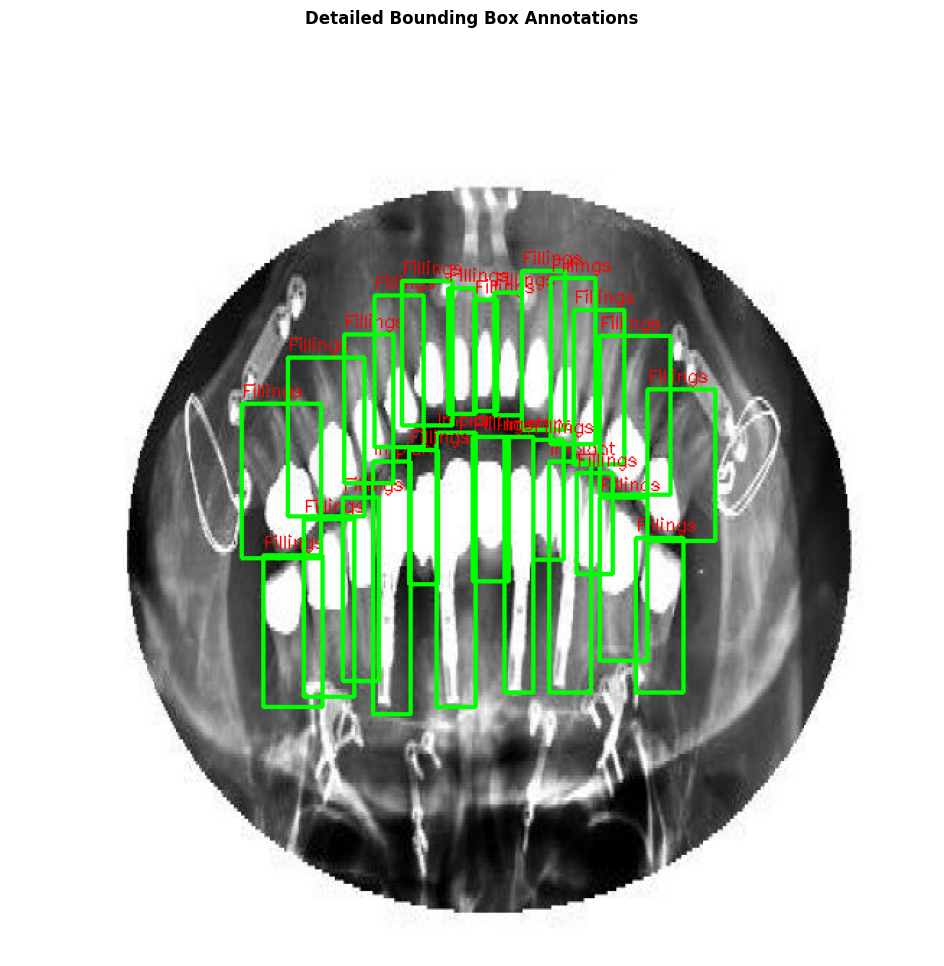

In [9]:
import cv2
import glob
import os
import matplotlib.pyplot as plt

# Image & target file path setup
target_img_path = None
target_label_path = None

for img_path in glob.glob('/content/dataset/train/images/*.[jJ][pP][gG]'):
    basename = os.path.splitext(os.path.basename(img_path))[0]
    label_path = f'/content/dataset/train/labels/{basename}.txt'
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
            if len(lines) == 26:
                target_img_path = img_path
                target_label_path = label_path
                break

# Render image with class labels
class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

if target_img_path:
    img = cv2.imread(target_img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    with open(target_label_path, 'r') as f:
        for line in f.readlines():
            cls, cx, cy, bw, bh = map(float, line.strip().split())
            xmin, ymin = int((cx - bw/2) * w), int((cy - bh/2) * h)
            xmax, ymax = int((cx + bw/2) * w), int((cy + bh/2) * h)

            label_name = class_map.get(int(cls), str(int(cls)))
            cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
            cv2.putText(img, label_name, (xmin, max(ymin - 5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

    plt.figure(figsize=(12, 12))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Detailed Bounding Box Annotations", fontsize=12, fontweight='bold')
    plt.show()

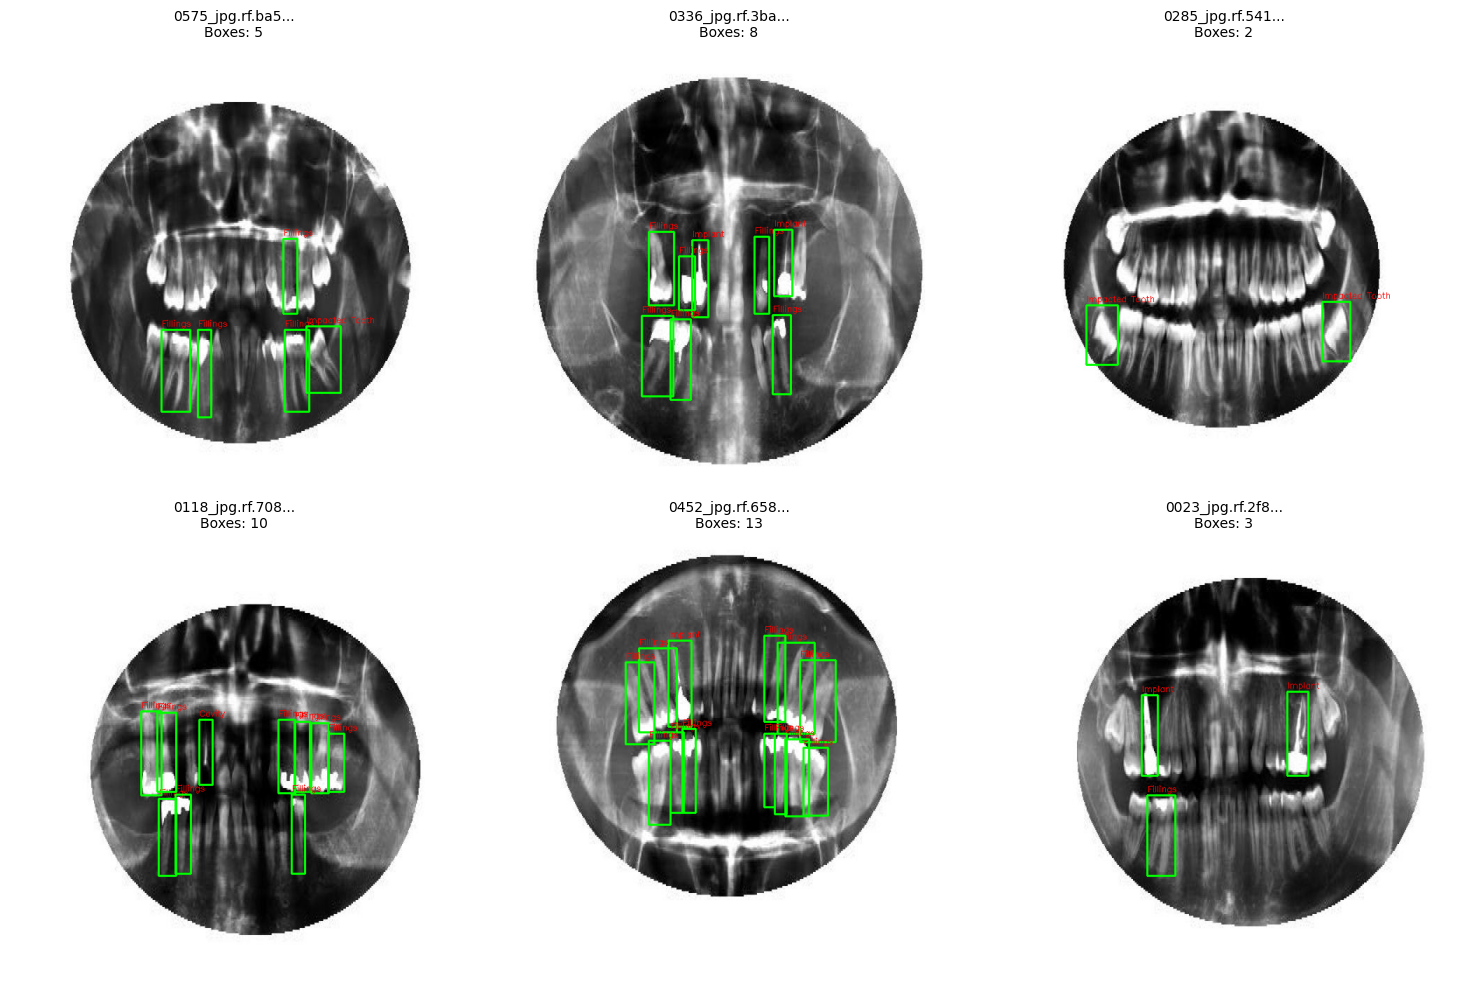

In [10]:
import cv2
import glob
import os
import random
import matplotlib.pyplot as plt

# 1. Map class IDs to names from your data.yaml
class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

# 2. Get all training images
image_paths = glob.glob('/content/dataset/train/images/*.[jJ][pP][gG]')
image_paths += glob.glob('/content/dataset/train/images/*.[pP][nN][gG]')

# Pick 6 random images
sampled_paths = random.sample(image_paths, min(6, len(image_paths)))

# 3. Plot grid
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx, img_path in enumerate(sampled_paths):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    basename = os.path.splitext(os.path.basename(img_path))[0]
    label_path = f'/content/dataset/train/labels/{basename}.txt'

    box_count = 0
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
            box_count = len(lines)
            for line in lines:
                cls, cx, cy, bw, bh = map(float, line.split())
                xmin = int((cx - bw / 2) * w)
                ymin = int((cy - bh / 2) * h)
                xmax = int((cx + bw / 2) * w)
                ymax = int((cy + bh / 2) * h)

                label_name = class_map.get(int(cls), f"ID {int(cls)}")
                cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
                cv2.putText(img, label_name, (xmin, max(ymin - 5, 12)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(f"{basename[:15]}...\nBoxes: {box_count}", fontsize=10)

plt.tight_layout()
plt.show()

              CLASS-LEVEL EXPLORATORY DATA ANALYSIS REPORT              
   Class Name (ID)  Images Count  Total Boxes Avg Box/Img Area Boxes/Image Ratio Width (Mean±Std) Height (Mean±Std)  Heavy Overlaps?
        Cavity (0)           163          398            0.70%              2.44    0.042 ± 0.016     0.160 ± 0.044 NO (Low Overlap)
      Fillings (1)           608         3692            0.86%              6.07    0.048 ± 0.017     0.177 ± 0.038 NO (Low Overlap)
Impacted Tooth (2)           186          316            0.86%              1.70    0.064 ± 0.014     0.132 ± 0.021 NO (Low Overlap)
       Implant (3)           400         1225            0.85%              3.06    0.044 ± 0.016     0.192 ± 0.037 NO (Low Overlap)


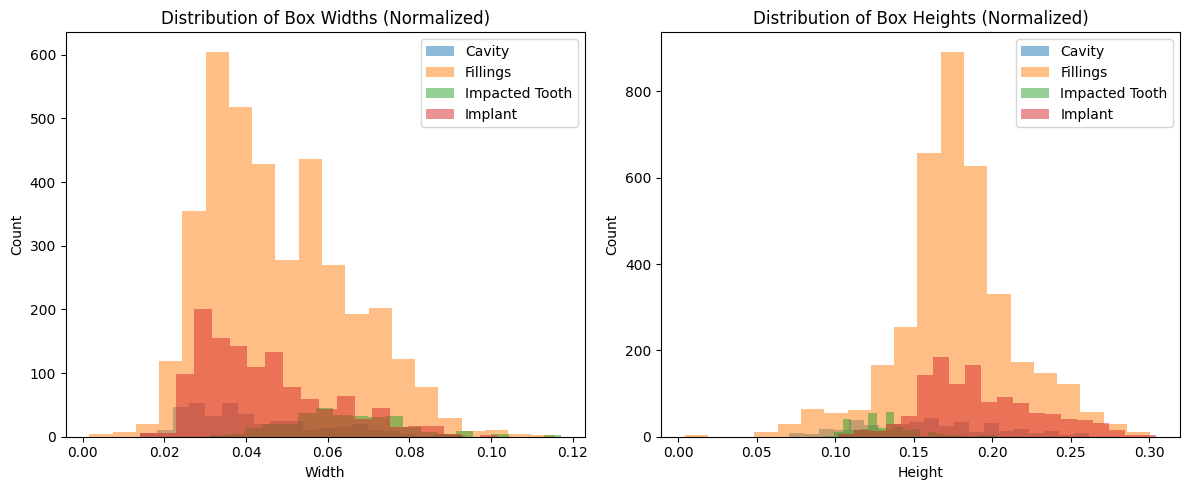

In [11]:
import glob
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# --- 1. LOAD CONFIG & CLASS MAP ---
yaml_path = '/content/dataset/data.yaml'
class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data_cfg = yaml.safe_load(f)
        names = data_cfg.get('names', {})
        if isinstance(names, list):
            class_map = {i: name for i, name in enumerate(names)}
        elif isinstance(names, dict):
            class_map = {int(k): v for k, v in names.items()}

# --- 2. PARSE DATASET METRICS ---
label_files = glob.glob('/content/dataset/train/labels/*.txt')
records = []
image_class_occurrences = {cls_id: set() for cls_id in class_map.keys()}

def compute_iou(box1, box2):
    """Calculates Intersection over Union (IoU) for overlapping annotations"""
    # Convert normalized cx, cy, w, h to xmin, ymin, xmax, ymax
    b1_x1, b1_x2 = box1[0] - box1[2]/2, box1[0] + box1[2]/2
    b1_y1, b1_y2 = box1[1] - box1[3]/2, box1[1] + box1[3]/2
    b2_x1, b2_x2 = box2[0] - box2[2]/2, box2[0] + box2[2]/2
    b2_y1, b2_y2 = box2[1] - box2[3]/2, box2[1] + box2[3]/2

    inter_x1 = max(b1_x1, b2_x1)
    inter_y1 = max(b1_y1, b2_y1)
    inter_x2 = min(b1_x2, b2_x2)
    inter_y2 = min(b1_y2, b2_y2)

    inter_area = max(0, inter_x2 - inter_x1) * max(0, inter_y2 - inter_y1)
    b1_area = box1[2] * box1[3]
    b2_area = box2[2] * box2[3]

    return inter_area / (b1_area + b2_area - inter_area + 1e-6)

overlap_counts = {cls_id: 0 for cls_id in class_map.keys()}

for label_path in label_files:
    fname = os.path.basename(label_path)
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    boxes_in_file = []
    for line in lines:
        cls_id = int(line[0])
        cx, cy, w, h = map(float, line[1:])
        norm_area = w * h  # Normalized box area relative to image area (1.0)

        records.append({
            'file': fname,
            'class_id': cls_id,
            'width': w,
            'height': h,
            'norm_area': norm_area
        })

        image_class_occurrences[cls_id].add(fname)
        boxes_in_file.append((cls_id, (cx, cy, w, h)))

    # Check for heavy box overlap within the same image (IoU > 0.4)
    for i in range(len(boxes_in_file)):
        for j in range(i + 1, len(boxes_in_file)):
            cls1, box1 = boxes_in_file[i]
            cls2, box2 = boxes_in_file[j]
            if compute_iou(box1, box2) > 0.4:
                overlap_counts[cls1] += 1
                if cls1 != cls2:
                    overlap_counts[cls2] += 1

df = pd.DataFrame(records)

# --- 3. DISPLAY COMPREHENSIVE TABLE PER CLASS ---
print("=" * 80)
print("              CLASS-LEVEL EXPLORATORY DATA ANALYSIS REPORT              ")
print("=" * 80)

summary_rows = []
for cls_id, cls_name in class_map.items():
    cls_df = df[df['class_id'] == cls_id] if not df.empty else pd.DataFrame()

    total_boxes = len(cls_df)
    images_containing = len(image_class_occurrences[cls_id])
    avg_area_pct = f"{cls_df['norm_area'].mean() * 100:.2f}%" if total_boxes > 0 else "0%"
    boxes_per_img = f"{total_boxes / images_containing:.2f}" if images_containing > 0 else "0"

    w_mean = f"{cls_df['width'].mean():.3f}" if total_boxes > 0 else "0"
    h_mean = f"{cls_df['height'].mean():.3f}" if total_boxes > 0 else "0"
    w_std = f"{cls_df['width'].std():.3f}" if total_boxes > 0 else "0"
    h_std = f"{cls_df['height'].std():.3f}" if total_boxes > 0 else "0"

    has_heavy_overlap = "YES (High Overlap)" if overlap_counts[cls_id] > 50 else "NO (Low Overlap)"

    summary_rows.append({
        'Class Name (ID)': f"{cls_name} ({cls_id})",
        'Images Count': images_containing,
        'Total Boxes': total_boxes,
        'Avg Box/Img Area': avg_area_pct,
        'Boxes/Image Ratio': boxes_per_img,
        'Width (Mean±Std)': f"{w_mean} ± {w_std}",
        'Height (Mean±Std)': f"{h_mean} ± {h_std}",
        'Heavy Overlaps?': has_heavy_overlap
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
print("=" * 80)

# --- 4. PLOT BOX DIMENSION DISTRIBUTIONS ---
if not df.empty:
    plt.figure(figsize=(12, 5))

    # Width distribution
    plt.subplot(1, 2, 1)
    for cls_id, cls_name in class_map.items():
        subset = df[df['class_id'] == cls_id]
        if not subset.empty:
            plt.hist(subset['width'], bins=20, alpha=0.5, label=cls_name)
    plt.title('Distribution of Box Widths (Normalized)')
    plt.xlabel('Width')
    plt.ylabel('Count')
    plt.legend()

    # Height distribution
    plt.subplot(1, 2, 2)
    for cls_id, cls_name in class_map.items():
        subset = df[df['class_id'] == cls_id]
        if not subset.empty:
            plt.hist(subset['height'], bins=20, alpha=0.5, label=cls_name)
    plt.title('Distribution of Box Heights (Normalized)')
    plt.xlabel('Height')
    plt.ylabel('Count')
    plt.legend()

    plt.tight_layout()
    plt.show()

           1. TRAIN VS VALIDATION CLASS DISTRIBUTION           
         Class  Train Boxes  Train Images  Val Boxes  Val Images Val/Train Ratio
        Cavity          398           163        144          49           36.2%
      Fillings         3692           608       1074         175           29.1%
Impacted Tooth          316           186         68          42           21.5%
       Implant         1225           400        371         118           30.3%

               2. CLASS CO-OCCURRENCE MATRIX (TRAIN)               
                Cavity  Fillings  Impacted Tooth  Implant
Cavity             163       140              31       88
Fillings           140       608              82      352
Impacted Tooth      31        82             186       62
Implant             88       352              62      400


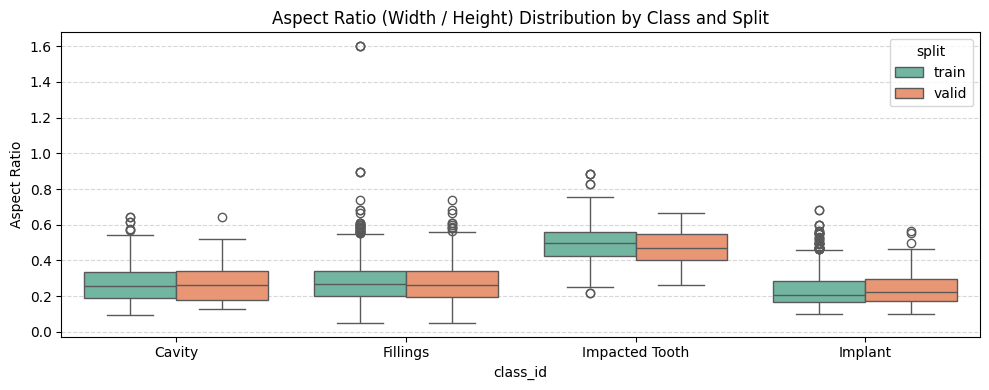

In [12]:
import glob
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data from Train and Valid splits
def load_split_data(split_name):
    label_files = glob.glob(f'/content/dataset/{split_name}/labels/*.txt')
    records = []
    file_classes = {}

    for label_path in label_files:
        fname = os.path.basename(label_path)
        file_classes[fname] = set()
        with open(label_path, 'r') as f:
            for line in f.readlines():
                if line.strip():
                    parts = line.strip().split()
                    cls_id = int(parts[0])
                    cx, cy, w, h = map(float, parts[1:])
                    records.append({
                        'split': split_name,
                        'file': fname,
                        'class_id': cls_id,
                        'width': w,
                        'height': h,
                        'aspect_ratio': w / (h + 1e-6),
                        'area': w * h
                    })
                    file_classes[fname].add(cls_id)
    return pd.DataFrame(records), file_classes

df_train, train_file_cls = load_split_data('train')
df_val, val_file_cls = load_split_data('valid')
df_all = pd.concat([df_train, df_val], ignore_index=True)

class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

# --- SPLIT COMPARISON TABLE ---
print("=" * 70)
print("           1. TRAIN VS VALIDATION CLASS DISTRIBUTION           ")
print("=" * 70)
split_summary = []
for cid, cname in class_map.items():
    tr_cnt = len(df_train[df_train['class_id'] == cid])
    val_cnt = len(df_val[df_val['class_id'] == cid])
    tr_imgs = sum(1 for s in train_file_cls.values() if cid in s)
    val_imgs = sum(1 for s in val_file_cls.values() if cid in s)
    split_summary.append({
        'Class': cname,
        'Train Boxes': tr_cnt,
        'Train Images': tr_imgs,
        'Val Boxes': val_cnt,
        'Val Images': val_imgs,
        'Val/Train Ratio': f"{(val_cnt/(tr_cnt+1e-5))*100:.1f}%"
    })
print(pd.DataFrame(split_summary).to_string(index=False))

# --- CLASS CO-OCCURRENCE MATRIX ---
print("\n" + "=" * 70)
print("               2. CLASS CO-OCCURRENCE MATRIX (TRAIN)               ")
print("=" * 70)
co_matrix = pd.DataFrame(0, index=class_map.values(), columns=class_map.values())
for classes in train_file_cls.values():
    for c1 in classes:
        for c2 in classes:
            co_matrix.loc[class_map[c1], class_map[c2]] += 1
print(co_matrix.to_string())

# --- ASPECT RATIO PLOTS ---
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_all, x='class_id', y='aspect_ratio', hue='split', palette='Set2')
plt.xticks(ticks=[0, 1, 2, 3], labels=class_map.values())
plt.title('Aspect Ratio (Width / Height) Distribution by Class and Split')
plt.ylabel('Aspect Ratio')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [13]:
# QC Flagging Pipeline
qc_results = []

for fname, classes in train_file_cls.items():
    img_boxes = df_train[df_train['file'] == fname]
    box_count = len(img_boxes)

    for idx, row in img_boxes.iterrows():
        flags = []
        if row['height'] > 0.22:
            flags.append("OVERSIZED_HEIGHT")
        if box_count > 15:
            flags.append("HIGH_DENSITY_IMAGE")
        if row['aspect_ratio'] < 0.2:
            flags.append("TALL_NARROW_BOX")
        if row['class_id'] == 3 and (row['height'] > 0.20 or box_count > 10):
            flags.append("SUSPICIOUS_IMPLANT")

        qc_results.append({
            'file': fname,
            'class_name': class_map[row['class_id']],
            'width': round(row['width'], 3),
            'height': round(row['height'], 3),
            'flags': ", ".join(flags) if flags else "CLEAN"
        })

df_qc = pd.DataFrame(qc_results)

print("=" * 70)
print("             3. AUTOMATED ANNOTATION QC SUMMARY              ")
print("=" * 70)
flag_counts = df_qc['flags'].value_counts()
print(flag_counts.to_string())
print("=" * 70)

             3. AUTOMATED ANNOTATION QC SUMMARY              
flags
CLEAN                                                                        2940
TALL_NARROW_BOX                                                               826
HIGH_DENSITY_IMAGE                                                            405
OVERSIZED_HEIGHT                                                              243
SUSPICIOUS_IMPLANT                                                            205
HIGH_DENSITY_IMAGE, TALL_NARROW_BOX                                           180
TALL_NARROW_BOX, SUSPICIOUS_IMPLANT                                           149
OVERSIZED_HEIGHT, TALL_NARROW_BOX                                             138
HIGH_DENSITY_IMAGE, TALL_NARROW_BOX, SUSPICIOUS_IMPLANT                       111
OVERSIZED_HEIGHT, TALL_NARROW_BOX, SUSPICIOUS_IMPLANT                         107
HIGH_DENSITY_IMAGE, SUSPICIOUS_IMPLANT                                        101
OVERSIZED_HEIGHT, SUSPICIOUS_I

#### The task here turned from Annotating the pathology to Annotating the teeth that contains it

#### Also very important: Filling has a really high boxes denisty across image sbut it presents in all datasets we found , also it can be medically approved in some cases but we will stil apply preprocessing and capping to outliers ISA

Successfully generated stratified sample of 50 images for Stage 2 Visual Audit.
Saved file list to '/content/audit_50_images.csv'


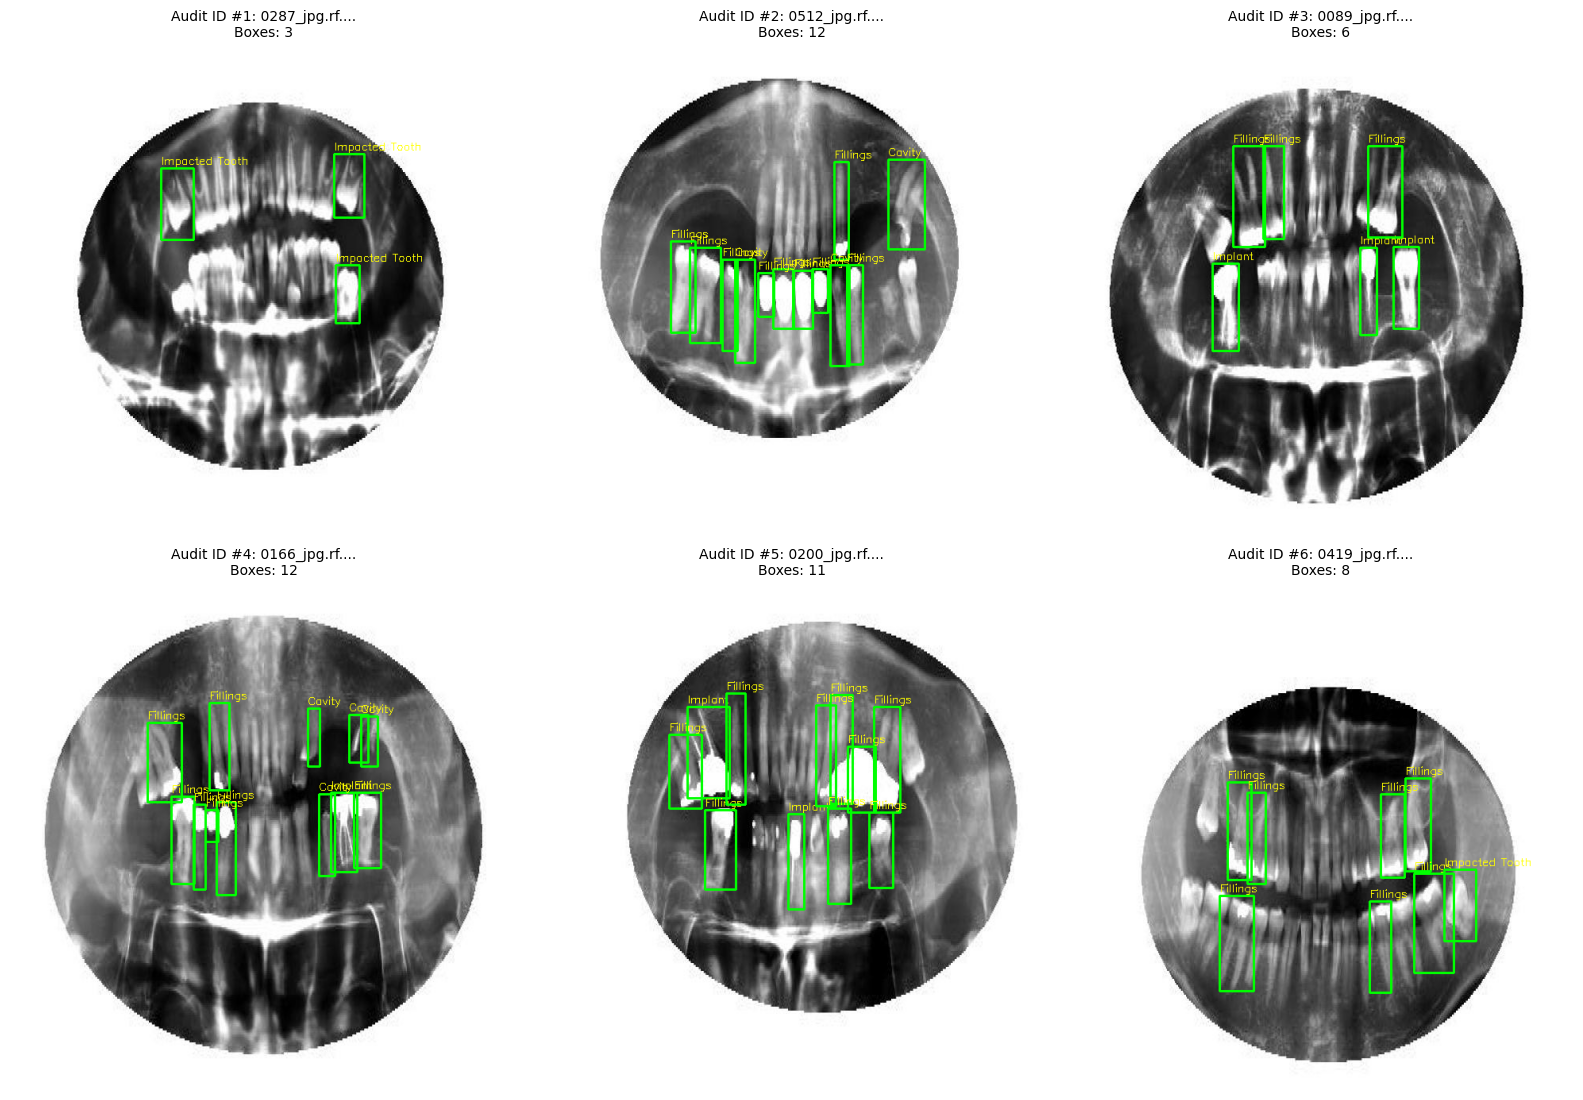

In [14]:
import random

# Stratified sampling: Select ~12-13 images per class to reach 50 unique images
random.seed(42)
audit_files = set()

for cid in class_map.keys():
    matching_files = [fname for fname, classes in train_file_cls.items() if cid in classes]
    sampled = random.sample(matching_files, min(13, len(matching_files)))
    audit_files.update(sampled)

audit_list = list(audit_files)[:50]

# Save audit list to CSV
df_audit_export = pd.DataFrame({'audit_file_id': range(1, len(audit_list) + 1), 'file_name': audit_list})
df_audit_export.to_csv('/content/audit_50_images.csv', index=False)

print(f"Successfully generated stratified sample of {len(audit_list)} images for Stage 2 Visual Audit.")
print("Saved file list to '/content/audit_50_images.csv'")

# Visualize Batch 1 (First 6 images of the Audit Set)
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.ravel()

for idx, fname in enumerate(audit_list[:6]):
    img_path = glob.glob(f'/content/dataset/train/images/{os.path.splitext(fname)[0]}.*')[0]
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    label_path = f'/content/dataset/train/labels/{fname}'
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    for line in lines:
        cls_id = int(line[0])
        cx, cy, bw, bh = map(float, line[1:])
        xmin, ymin = int((cx - bw/2) * w), int((cy - bh/2) * h)
        xmax, ymax = int((cx + bw/2) * w), int((cy + bh/2) * h)

        cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
        cv2.putText(img, class_map[cls_id], (xmin, max(ymin - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 0), 1)

    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(f"Audit ID #{idx+1}: {fname[:12]}...\nBoxes: {len(lines)}", fontsize=10)

plt.tight_layout()
plt.show()

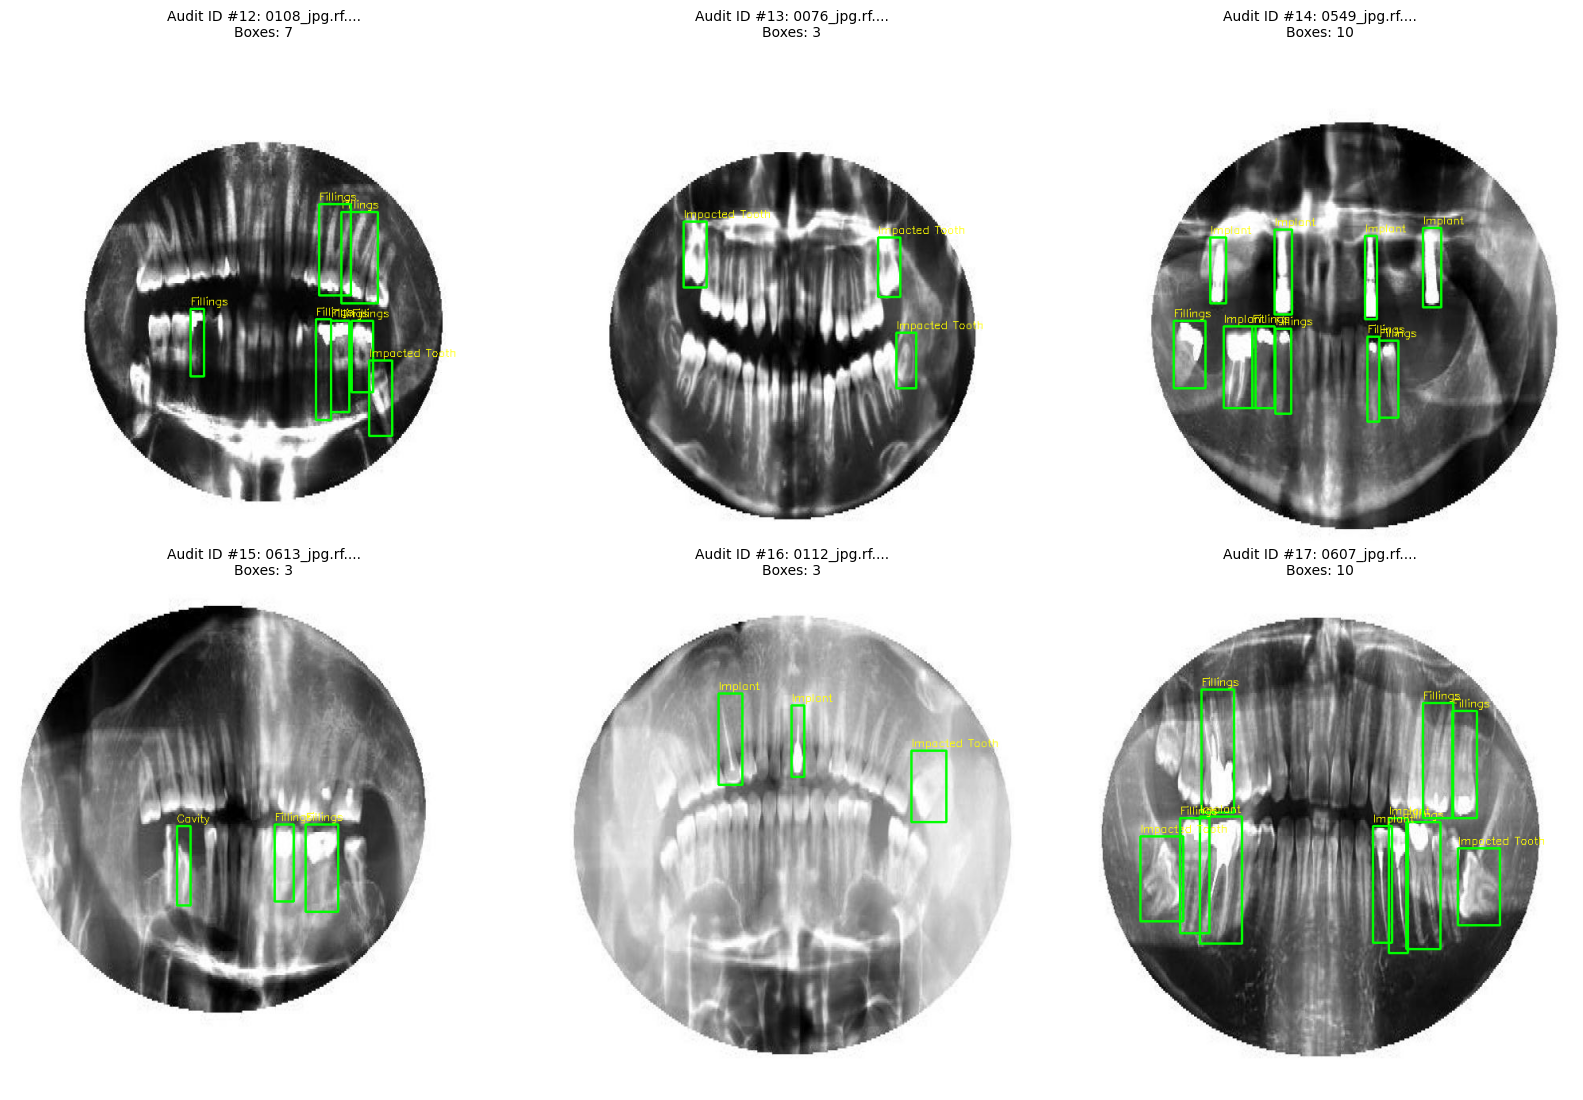

In [15]:
import cv2
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load the generated audit list
df_audit = pd.read_csv('/content/audit_50_images.csv')
audit_list = df_audit['file_name'].tolist()

class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.ravel()

# Render Batch 2 (Images 7 to 12)
for idx, fname in enumerate(audit_list[13:19]):
    img_path = glob.glob(f'/content/dataset/train/images/{os.path.splitext(fname)[0]}.*')[0]
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    label_path = f'/content/dataset/train/labels/{fname}'
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    for line in lines:
        cls_id = int(line[0])
        cx, cy, bw, bh = map(float, line[1:])
        xmin, ymin = int((cx - bw/2) * w), int((cy - bh/2) * h)
        xmax, ymax = int((cx + bw/2) * w), int((cy + bh/2) * h)

        cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
        cv2.putText(img, class_map[cls_id], (xmin, max(ymin - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 0), 1)

    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(f"Audit ID #{idx+12}: {fname[:12]}...\nBoxes: {len(lines)}", fontsize=10)

plt.tight_layout()
plt.show()

#### in Implant there are so many implants in some images that are severly misclassified, we can filter it by removing images that contains many implants as its not so many images

#### Same in Cavity, we gonna filter it also but with a different threshold, medical wise

Safely created workspace copy at '/content/dataset_cleaned'
Found 753 label files for analysis.
        IMPLANT COUNT DISTRIBUTION PER IMAGE (TRAIN)        
Total images containing at least 1 Implant: 400
Max implants in a single image:           17
Average implants per image (when present): 3.06
------------------------------------------------------------
Threshold (> N Implants)  Images Flagged % of Total Train Set Deleted
            > 2 Implants             168                       22.31%
            > 4 Implants              73                        9.69%
            > 6 Implants              47                        6.24%
            > 8 Implants              23                        3.05%
           > 10 Implants              11                        1.46%
           > 12 Implants               3                        0.40%


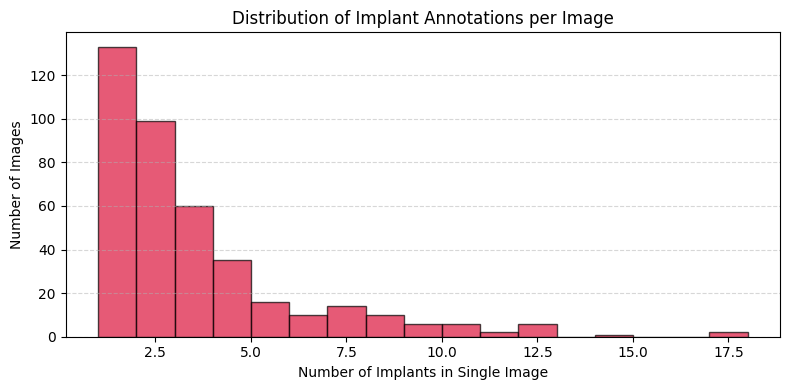

In [16]:
import glob
import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt

# 1. Ensure fresh, non-destructive workspace copy
source_dir = '/content/dataset'
target_dir = '/content/dataset_cleaned'

if not os.path.exists(target_dir):
    shutil.copytree(source_dir, target_dir)
    print("Safely created workspace copy at '/content/dataset_cleaned'")

# 2. Search dynamically for train labels across common directory patterns
label_files = glob.glob('/content/dataset_cleaned/train/labels/*.[tT][xX][tT]')
if not label_files:
    label_files = glob.glob('/content/dataset_cleaned/labels/train/*.[tT][xX][tT]')
if not label_files:
    label_files = glob.glob('/content/dataset_cleaned/**/train/labels/*.[tT][xX][tT]', recursive=True)

print(f"Found {len(label_files)} label files for analysis.")

if len(label_files) == 0:
    print("ERROR: Still cannot locate label files! Please check your dataset path.")
else:
    implant_counts_per_image = []

    for label_path in label_files:
        with open(label_path, 'r') as f:
            lines = [l.strip().split() for l in f.readlines() if l.strip()]

        # Class ID 3 = Implant
        implants = sum(1 for line in lines if int(line[0]) == 3)
        if implants > 0:
            implant_counts_per_image.append(implants)

    df_imp = pd.Series(implant_counts_per_image)

    print("=" * 60)
    print("        IMPLANT COUNT DISTRIBUTION PER IMAGE (TRAIN)        ")
    print("=" * 60)
    print(f"Total images containing at least 1 Implant: {len(df_imp)}")
    if len(df_imp) > 0:
        print(f"Max implants in a single image:           {df_imp.max()}")
        print(f"Average implants per image (when present): {df_imp.mean():.2f}")
    print("-" * 60)

    # Evaluate threshold impact
    thresholds = [2, 4, 6, 8, 10, 12]
    impact_summary = []

    total_files = len(label_files)
    for t in thresholds:
        num_exceeded = sum(1 for c in implant_counts_per_image if c > t)
        pct_lost = (num_exceeded / total_files) * 100 if total_files > 0 else 0
        impact_summary.append({
            'Threshold (> N Implants)': f"> {t} Implants",
            'Images Flagged': num_exceeded,
            '% of Total Train Set Deleted': f"{pct_lost:.2f}%"
        })

    print(pd.DataFrame(impact_summary).to_string(index=False))
    print("=" * 60)

    # Plot histogram if data exists
    if len(df_imp) > 0:
        plt.figure(figsize=(8, 4))
        plt.hist(implant_counts_per_image, bins=range(1, df_imp.max() + 2), color='crimson', edgecolor='black', alpha=0.7)
        plt.title('Distribution of Implant Annotations per Image')
        plt.xlabel('Number of Implants in Single Image')
        plt.ylabel('Number of Images')
        plt.grid(axis='y', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

          PATHOLOGY DISTRIBUTION & PROPOSED CLINICAL THRESHOLDS          
         Class  Images w/ Class  Max in 1 Img Mean Count Proposed Limit  Images Flagged % Dataset Lost
        Cavity              163            19       2.44            > 6               8          1.06%
      Fillings              608            22       6.07           > 16               5          0.66%
Impacted Tooth              186             4       1.70            > 4               0          0.00%
       Implant              400            17       3.06            > 6              47          6.24%


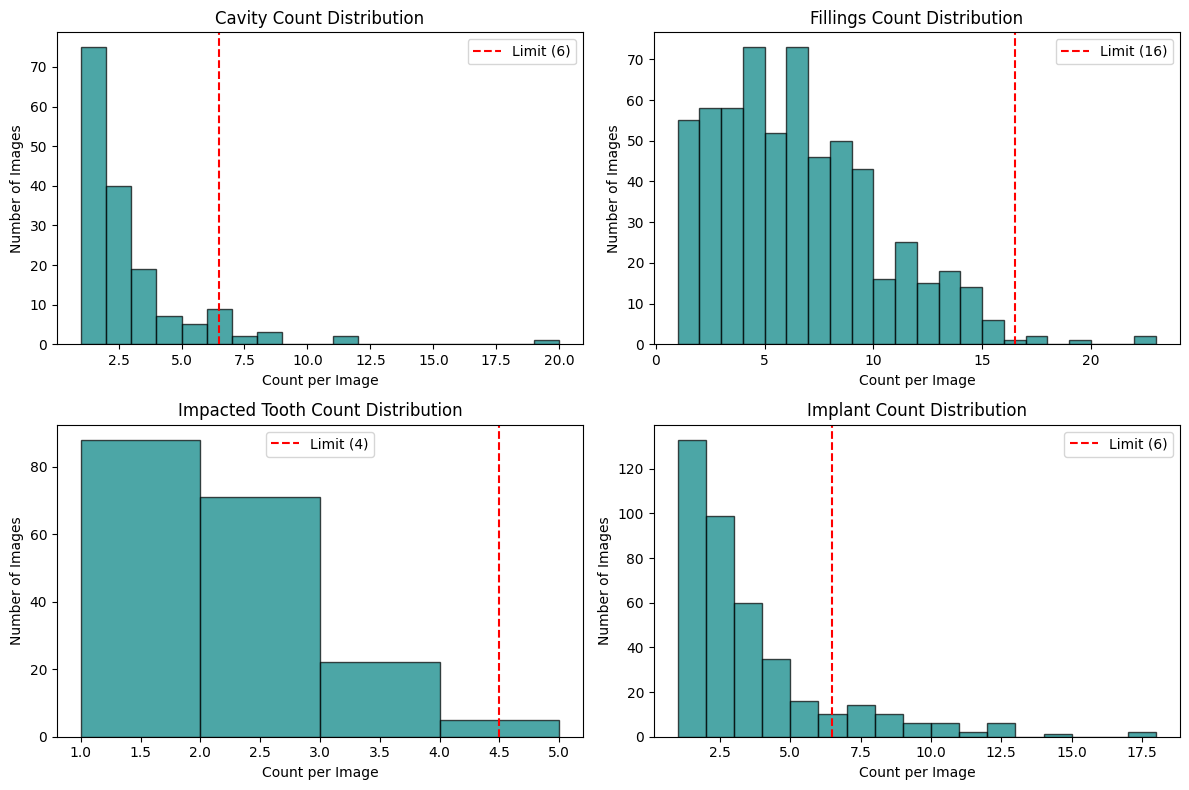

In [17]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

label_files = glob.glob('/content/dataset_cleaned/train/labels/*.[tT][xX][tT]')

class_counts = {
    'Cavity': [],
    'Fillings': [],
    'Impacted Tooth': [],
    'Implant': []
}

class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

for label_path in label_files:
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    counts = {0: 0, 1: 0, 2: 0, 3: 0}
    for line in lines:
        cls_id = int(line[0])
        if cls_id in counts:
            counts[cls_id] += 1

    for cls_id, cname in class_map.items():
        if counts[cls_id] > 0:
            class_counts[cname].append(counts[cls_id])

# Summary Table
print("=" * 75)
print("          PATHOLOGY DISTRIBUTION & PROPOSED CLINICAL THRESHOLDS          ")
print("=" * 75)

summary_data = []
# Clinical threshold bounds for Task B
proposed_limits = {
    'Cavity': 6,
    'Fillings': 16,
    'Impacted Tooth': 4,
    'Implant': 6
}

for cname, counts in class_counts.items():
    series = pd.Series(counts)
    limit = proposed_limits[cname]
    exceeded = sum(1 for x in counts if x > limit)
    pct_impact = (exceeded / len(label_files)) * 100

    summary_data.append({
        'Class': cname,
        'Images w/ Class': len(series),
        'Max in 1 Img': series.max() if len(series) > 0 else 0,
        'Mean Count': f"{series.mean():.2f}" if len(series) > 0 else "0",
        'Proposed Limit': f"> {limit}",
        'Images Flagged': exceeded,
        '% Dataset Lost': f"{pct_impact:.2f}%"
    })

df_summary = pd.DataFrame(summary_data)
print(df_summary.to_string(index=False))
print("=" * 75)

# Plot Distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for idx, (cname, counts) in enumerate(class_counts.items()):
    axes[idx].hist(counts, bins=range(1, max(counts)+2 if counts else 2), color='teal', edgecolor='black', alpha=0.7)
    axes[idx].axvline(proposed_limits[cname] + 0.5, color='red', linestyle='--', label=f'Limit ({proposed_limits[cname]})')
    axes[idx].set_title(f'{cname} Count Distribution')
    axes[idx].set_xlabel('Count per Image')
    axes[idx].set_ylabel('Number of Images')
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [18]:
import glob
import os
import pandas as pd

label_files = glob.glob('/content/dataset_cleaned/train/labels/*.[tT][xX][tT]')

# Unified Clinical Limits
LIMITS = {
    0: 6,   # Cavity
    1: 16,  # Fillings
    2: 4,   # Impacted Tooth
    3: 6    # Implant
}

removed_files = []

for label_path in label_files:
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    counts = {0: 0, 1: 0, 2: 0, 3: 0}
    for line in lines:
        cls_id = int(line[0])
        if cls_id in counts:
            counts[cls_id] += 1

    # Check if ANY class exceeds its clinical threshold
    is_corrupted = any(counts[cls_id] > LIMITS[cls_id] for cls_id in counts)

    if is_corrupted:
        basename = os.path.splitext(os.path.basename(label_path))[0]
        img_matches = glob.glob(f'/content/dataset_cleaned/train/images/{basename}.*')

        # Remove label and corresponding image
        if os.path.exists(label_path):
            os.remove(label_path)
        if img_matches and os.path.exists(img_matches[0]):
            os.remove(img_matches[0])

        removed_files.append((basename, counts))

print("=" * 70)
print("                   UNIFIED CLEANING SUMMARY                     ")
print("=" * 70)
print(f"Total images removed across ALL clinical rules: {len(removed_files)}")
print(f"Remaining clean training images:               {len(label_files) - len(removed_files)}")
print(f"Final Dataset Loss Percentage:                 {(len(removed_files)/len(label_files))*100:.2f}%")
print("=" * 70)

                   UNIFIED CLEANING SUMMARY                     
Total images removed across ALL clinical rules: 60
Remaining clean training images:               693
Final Dataset Loss Percentage:                 7.97%


In [19]:
import glob
import os
import pandas as pd

def compute_iou(box1, box2):
    b1_x1, b1_x2 = box1[0] - box1[2]/2, box1[0] + box1[2]/2
    b1_y1, b1_y2 = box1[1] - box1[3]/2, box1[1] + box1[3]/2
    b2_x1, b2_x2 = box2[0] - box2[2]/2, box2[0] + box2[2]/2
    b2_y1, b2_y2 = box2[1] - box2[3]/2, box2[1] + box2[3]/2

    inter_x1 = max(b1_x1, b2_x1)
    inter_y1 = max(b1_y1, b2_y1)
    inter_x2 = min(b1_x2, b2_x2)
    inter_y2 = min(b1_y2, b2_y2)

    inter_area = max(0, inter_x2 - inter_x1) * max(0, inter_y2 - inter_y1)
    b1_area = box1[2] * box1[3]
    b2_area = box2[2] * box2[3]

    return inter_area / (b1_area + b2_area - inter_area + 1e-6)

label_files = glob.glob('/content/dataset_cleaned/train/labels/*.[tT][xX][tT]')
class_map = {0: 'Cavity', 1: 'Fillings', 2: 'Impacted Tooth', 3: 'Implant'}

same_class_duplicates = 0
cross_class_overlaps = 0
affected_files = set()

for label_path in label_files:
    fname = os.path.basename(label_path)
    with open(label_path, 'r') as f:
        lines = [l.strip().split() for l in f.readlines() if l.strip()]

    boxes = []
    for line in lines:
        cls_id = int(line[0])
        cx, cy, w, h = map(float, line[1:])
        boxes.append((cls_id, (cx, cy, w, h)))

    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            cls1, b1 = boxes[i]
            cls2, b2 = boxes[j]
            iou = compute_iou(b1, b2)

            if iou > 0.60:  # 60% spatial overlap threshold
                affected_files.add(fname)
                if cls1 == cls2:
                    same_class_duplicates += 1
                else:
                    cross_class_overlaps += 1

print("=" * 65)
print("             SPATIAL DUPLICATE & OVERLAP AUDIT                 ")
print("=" * 65)
print(f"Total images with high-overlap boxes (>60% IoU): {len(affected_files)}")
print(f"Same-class redundant duplicate boxes:             {same_class_duplicates}")
print(f"Cross-class overlapping boxes:                   {cross_class_overlaps}")
print("=" * 65)

             SPATIAL DUPLICATE & OVERLAP AUDIT                 
Total images with high-overlap boxes (>60% IoU): 26
Same-class redundant duplicate boxes:             0
Cross-class overlapping boxes:                   33


#### No NON_MAX_SUPRESSION needed

#### Now its time to get a new data to act as BackGround healthy teeth

#### We wll use it in some EDA so if its better we will take it instead

In [20]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="BT7ZDqpVr0lshKVVQZ0x")
project = rf.workspace("opg-unbmz").project("dental-x-ray-panoramic")
version = project.version(2)
dataset = version.download("yolov11")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.1
    Uninstalling typer-0.27.1:
      Successfully uninstalled typer-0.27.1
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental-x-ray-panoramic-2 in yolov11:: 100%|██████████| 27382/27382 [00:08<00:00, 3242.36it/s]


✅ Successfully converted polygon annotations to Bounding Boxes in 13685 label files!

TOTAL CLASSES DETECTED (31):
  Class 0: Bone Loss
  Class 1: Caries
  Class 2: Crown
  Class 3: Cyst
  Class 4: Filling
  Class 5: Fracture teeth
  Class 6: Implant
  Class 7: Malaligned
  Class 8: Mandibular Canal
  Class 9: Missing teeth
  Class 10: Periapical lesion
  Class 11: Permanent Teeth
  Class 12: Primary teeth
  Class 13: Retained root
  Class 14: Root Canal Treatment
  Class 15: Root Piece
  Class 16: Root resorption
  Class 17: Supra Eruption
  Class 18: TAD
  Class 19: abutment
  Class 20: attrition
  Class 21: bone defect
  Class 22: gingival former
  Class 23: impacted tooth
  Class 24: maxillary sinus
  Class 25: metal band
  Class 26: orthodontic brackets
  Class 27: permanent retainer
  Class 28: plating
  Class 29: post - core
  Class 30: wire

📊 TOTAL ANNOTATION INSTANCES: 134733
split
train    94733
valid    26517
test     13483
Name: count, dtype: int64




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



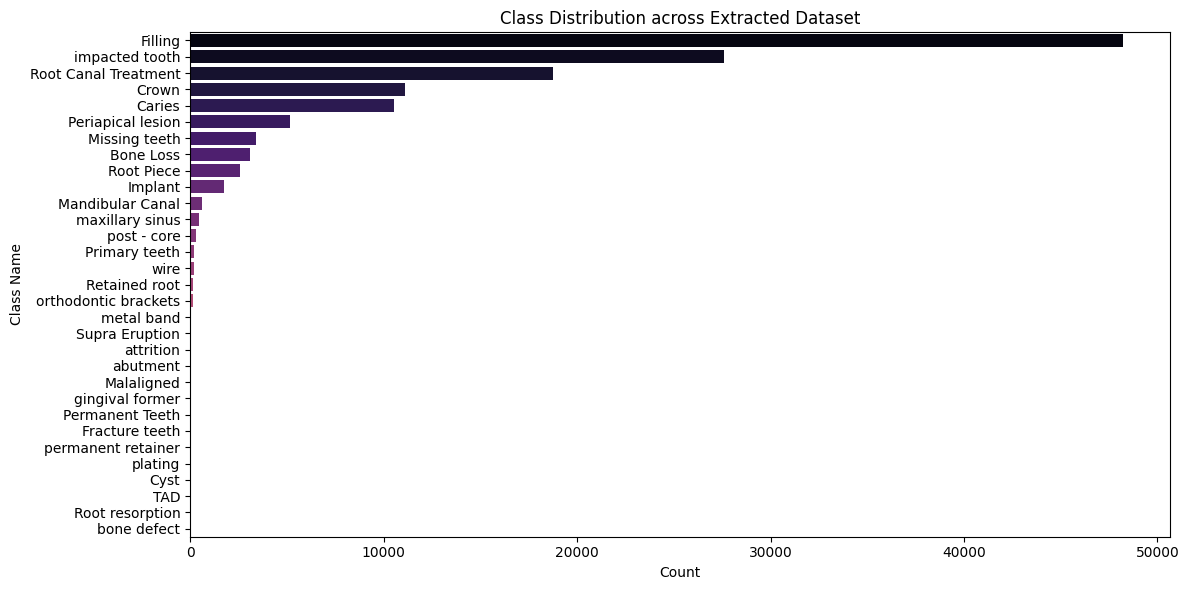

In [21]:
import glob
import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Robust Polygon to Bounding Box Converter
def seg_to_bbox(line):
    parts = line.strip().split()
    if not parts:
        return None

    # Check if the line starts with a valid numeric class ID
    try:
        cls_id = int(parts[0])
        coords = [float(x) for x in parts[1:]]
    except ValueError:
        return None  # Skip non-label lines safely

    if len(coords) < 4:
        return None # Invalid annotation format

    if len(coords) == 4: # Already standard bbox format: cx cy w h
        return line.strip()

    # Polygon to Bounding Box conversion: min/max x and y
    xs = coords[0::2]
    ys = coords[1::2]

    xmin, xmax = min(xs), max(xs)
    ymin, ymax = min(ys), max(ys)

    cx = (xmin + xmax) / 2.0
    cy = (ymin + ymax) / 2.0
    w = xmax - xmin
    h = ymax - ymin

    return f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}"

# Process ONLY valid label directories across splits
converted_count = 0
for split in ['train', 'valid', 'test']:
    label_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for label_path in label_files:
        with open(label_path, 'r') as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            converted = seg_to_bbox(line)
            if converted:
                new_lines.append(converted)

        with open(label_path, 'w') as f:
            f.write("\n".join(new_lines))
        converted_count += 1

print(f"✅ Successfully converted polygon annotations to Bounding Boxes in {converted_count} label files!\n")

# 2. Dataset EDA
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get('names', [])

print("=" * 60)
print(f"TOTAL CLASSES DETECTED ({len(class_names)}):")
for idx, name in enumerate(class_names):
    print(f"  Class {idx}: {name}")
print("=" * 60)

records = []
for split in ['train', 'valid', 'test']:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    try:
                        cls_id = int(parts[0])
                        w, h = float(parts[3]), float(parts[4])
                        records.append({
                            'split': split,
                            'class_id': cls_id,
                            'class_name': class_names[cls_id] if cls_id < len(class_names) else str(cls_id),
                            'bbox_width': w,
                            'bbox_height': h
                        })
                    except ValueError:
                        continue

df = pd.DataFrame(records)

print(f"\n📊 TOTAL ANNOTATION INSTANCES: {len(df)}")
print(df['split'].value_counts())

# Plot Class Distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='class_name', order=df['class_name'].value_counts().index, palette='magma')
plt.title('Class Distribution across Extracted Dataset')
plt.xlabel('Count')
plt.ylabel('Class Name')
plt.tight_layout()
plt.show()

In [22]:
import glob
import yaml
import os

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Define only the classes you actually want to keep
KEEP_CLASSES = [
    'Filling',
    'impacted tooth',
    'Root Canal Treatment',
    'Crown',
    'Caries',
    'Periapical lesion',
    'Missing teeth',
    'Bone Loss',
    'Root Piece',
    'Implant'
]

# Create old_id -> new_id map
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    old_cfg = yaml.safe_load(f)

old_names = old_cfg.get('names', [])
id_map = {}
new_names = []

for new_idx, class_name in enumerate(KEEP_CLASSES):
    if class_name in old_names:
        old_idx = old_names.index(class_name)
        id_map[old_idx] = new_idx
        new_names.append(class_name)

# 2. Filter and update label files
filtered_boxes = 0
for split in ['train', 'valid', 'test']:
    label_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for label_path in label_files:
        with open(label_path, 'r') as f:
            lines = f.readlines()

        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            old_cls = int(parts[0])
            if old_cls in id_map:
                new_cls = id_map[old_cls]
                filtered_lines.append(f"{new_cls} {' '.join(parts[1:])}")
                filtered_boxes += 1

        with open(label_path, 'w') as f:
            f.write("\n".join(filtered_lines))

# 3. Save clean data.yaml
clean_cfg = {
    'path': extract_dir,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': len(new_names),
    'names': new_names
}

with open(yaml_path, 'w') as f:
    yaml.dump(clean_cfg, f)

print(f"✅ Filtered dataset to top {len(new_names)} active classes!")
print(f"Remaining valid bounding box annotations: {filtered_boxes}")

✅ Filtered dataset to top 10 active classes!
Remaining valid bounding box annotations: 132316


Total Classes Found: 10
Class ID 0: Filling
Class ID 1: impacted tooth
Class ID 2: Root Canal Treatment
Class ID 3: Crown
Class ID 4: Caries
Class ID 5: Periapical lesion
Class ID 6: Missing teeth
Class ID 7: Bone Loss
Class ID 8: Root Piece
Class ID 9: Implant




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



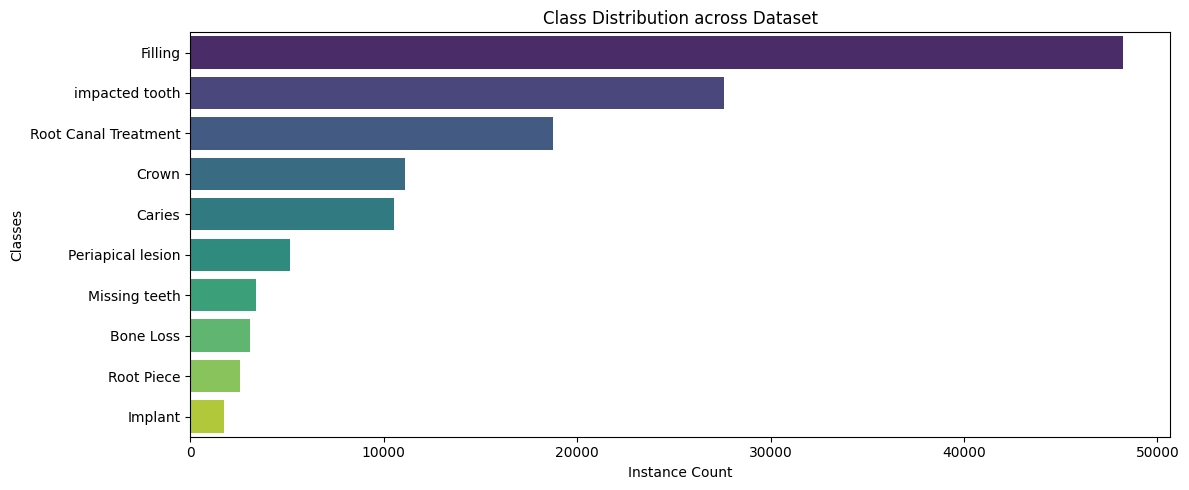

DATASET EDA SUMMARY
Total Object Instances: 132316
Instances per split:
split
train    93015
valid    26011
test     13290
Name: count, dtype: int64


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

# Read data.yaml mapping
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get('names', [])
print("=" * 60)
print(f"Total Classes Found: {len(class_names)}")
for idx, name in enumerate(class_names):
    print(f"Class ID {idx}: {name}")
print("=" * 60)

# Parse bounding box metrics
records = []
splits = ['train', 'valid', 'test']

for split in splits:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            lines = [line.strip().split() for line in f if line.strip()]

        for line in lines:
            cls_id = int(line[0])
            w, h = float(line[3]), float(line[4])
            records.append({
                'split': split,
                'class_id': cls_id,
                'class_name': class_names[cls_id] if cls_id < len(class_names) else str(cls_id),
                'bbox_width': w,
                'bbox_height': h,
                'bbox_area': w * h
            })

df = pd.DataFrame(records)

# Plot Class Distribution
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y='class_name', order=df['class_name'].value_counts().index, palette='viridis')
plt.title('Class Distribution across Dataset')
plt.xlabel('Instance Count')
plt.ylabel('Classes')
plt.tight_layout()
plt.show()

# Summary Metrics
print("DATASET EDA SUMMARY")
print(f"Total Object Instances: {len(df)}")
print(f"Instances per split:\n{df['split'].value_counts()}")

In [24]:
import glob
import yaml

extract_dir = "/content/dental-x-ray-panoramic-2"

# Define the selected 4 classes
TOP_4_CLASSES = [
    'impacted tooth',
    'Root Canal Treatment',
    'Crown',
    'Caries'
]

yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    old_cfg = yaml.safe_load(f)

old_names = old_cfg.get('names', [])
id_map = {}
new_names = []

# Map old indices to new 0-3 indices
for new_idx, class_name in enumerate(TOP_4_CLASSES):
    if class_name in old_names:
        old_idx = old_names.index(class_name)
        id_map[old_idx] = new_idx
        new_names.append(class_name)

# Filter label text files
filtered_boxes = 0
for split in ['train', 'valid', 'test']:
    label_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for label_path in label_files:
        with open(label_path, 'r') as f:
            lines = f.readlines()

        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            old_cls = int(parts[0])
            if old_cls in id_map:
                new_cls = id_map[old_cls]
                filtered_lines.append(f"{new_cls} {' '.join(parts[1:])}")
                filtered_boxes += 1

        with open(label_path, 'w') as f:
            f.write("\n".join(filtered_lines))

# Save updated data.yaml
clean_cfg = {
    'path': extract_dir,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': len(new_names),
    'names': new_names
}

with open(yaml_path, 'w') as f:
    yaml.dump(clean_cfg, f)

print(f"✅ Dataset successfully filtered to 4 classes: {new_names}")
print(f"Total remaining annotations: {filtered_boxes}")

✅ Dataset successfully filtered to 4 classes: ['impacted tooth', 'Root Canal Treatment', 'Crown', 'Caries']
Total remaining annotations: 68023


✅ Filtered dataset to 4 classes: ['impacted tooth', 'Root Canal Treatment', 'Crown', 'Caries']

📊 FINAL 4-CLASS DATASET EDA SUMMARY
Total Bounding Box Annotations: 68023

Instances per Split:
split
train    47904
valid    13294
test      6825
Name: count, dtype: int64

Instances per Class:
class_name
impacted tooth          27600
Root Canal Treatment    18771
Crown                   11106
Caries                  10546
Name: count, dtype: int64


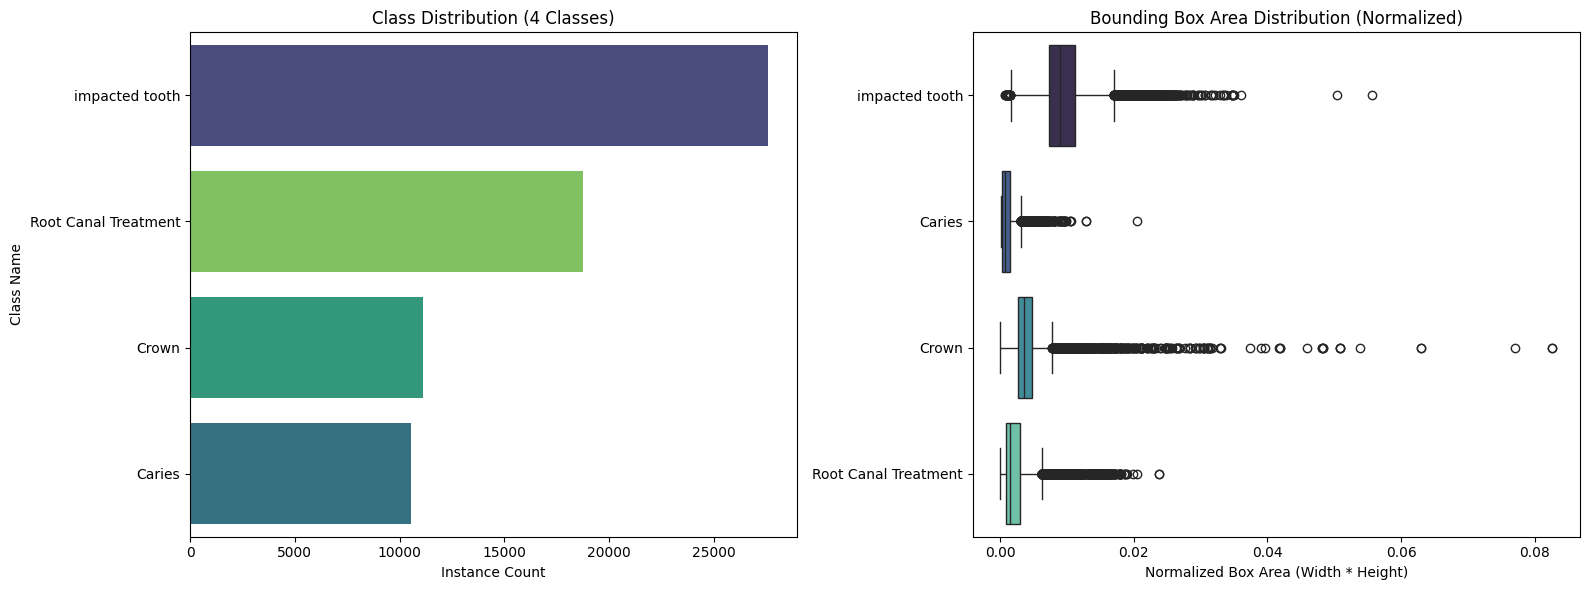

In [25]:
import glob
import os
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Target 4 Classes
TOP_4_CLASSES = [
    'impacted tooth',
    'Root Canal Treatment',
    'Crown',
    'Caries'
]

yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    old_cfg = yaml.safe_load(f)

old_names = old_cfg.get('names', [])
id_map = {}
new_names = []

for new_idx, class_name in enumerate(TOP_4_CLASSES):
    if class_name in old_names:
        old_idx = old_names.index(class_name)
        id_map[old_idx] = new_idx
        new_names.append(class_name)

# Filter label text files to 4 target classes
filtered_boxes = 0
for split in ['train', 'valid', 'test']:
    label_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for label_path in label_files:
        with open(label_path, 'r') as f:
            lines = f.readlines()

        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            try:
                old_cls = int(parts[0])
                if old_cls in id_map:
                    new_cls = id_map[old_cls]
                    filtered_lines.append(f"{new_cls} {' '.join(parts[1:])}")
                    filtered_boxes += 1
            except ValueError:
                continue

        with open(label_path, 'w') as f:
            f.write("\n".join(filtered_lines))

# Save updated clean data.yaml
clean_cfg = {
    'path': extract_dir,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'nc': len(new_names),
    'names': new_names
}

with open(yaml_path, 'w') as f:
    yaml.dump(clean_cfg, f)

print(f"✅ Filtered dataset to 4 classes: {new_names}")

# 2. Complete EDA Metrics Extraction
records = []
for split in ['train', 'valid', 'test']:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    try:
                        cls_id = int(parts[0])
                        w, h = float(parts[3]), float(parts[4])
                        records.append({
                            'split': split,
                            'class_id': cls_id,
                            'class_name': new_names[cls_id],
                            'bbox_width': w,
                            'bbox_height': h,
                            'bbox_area': w * h,
                            'aspect_ratio': w / h if h > 0 else 0
                        })
                    except (ValueError, IndexError):
                        continue

df = pd.DataFrame(records)

# Print Summary
print("\n" + "="*50)
print("📊 FINAL 4-CLASS DATASET EDA SUMMARY")
print("="*50)
print(f"Total Bounding Box Annotations: {len(df)}")
print("\nInstances per Split:")
print(df['split'].value_counts())
print("\nInstances per Class:")
print(df['class_name'].value_counts())

# 3. Visualization Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Class Distribution (Fixing Seaborn Deprecation Warning)
sns.countplot(
    data=df,
    y='class_name',
    hue='class_name',
    legend=False,
    order=df['class_name'].value_counts().index,
    palette='viridis',
    ax=axes[0]
)
axes[0].set_title('Class Distribution (4 Classes)')
axes[0].set_xlabel('Instance Count')
axes[0].set_ylabel('Class Name')

# Bounding Box Area Scatter / Density Analysis
sns.boxplot(
    data=df,
    x='bbox_area',
    y='class_name',
    hue='class_name',
    legend=False,
    palette='mako',
    ax=axes[1]
)
axes[1].set_title('Bounding Box Area Distribution (Normalized)')
axes[1].set_xlabel('Normalized Box Area (Width * Height)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


Original Bounding Boxes: 68023
Cleaned Bounding Boxes (Post-IQR Outlier Removal): 63353
Removed Outliers: 4670 instances


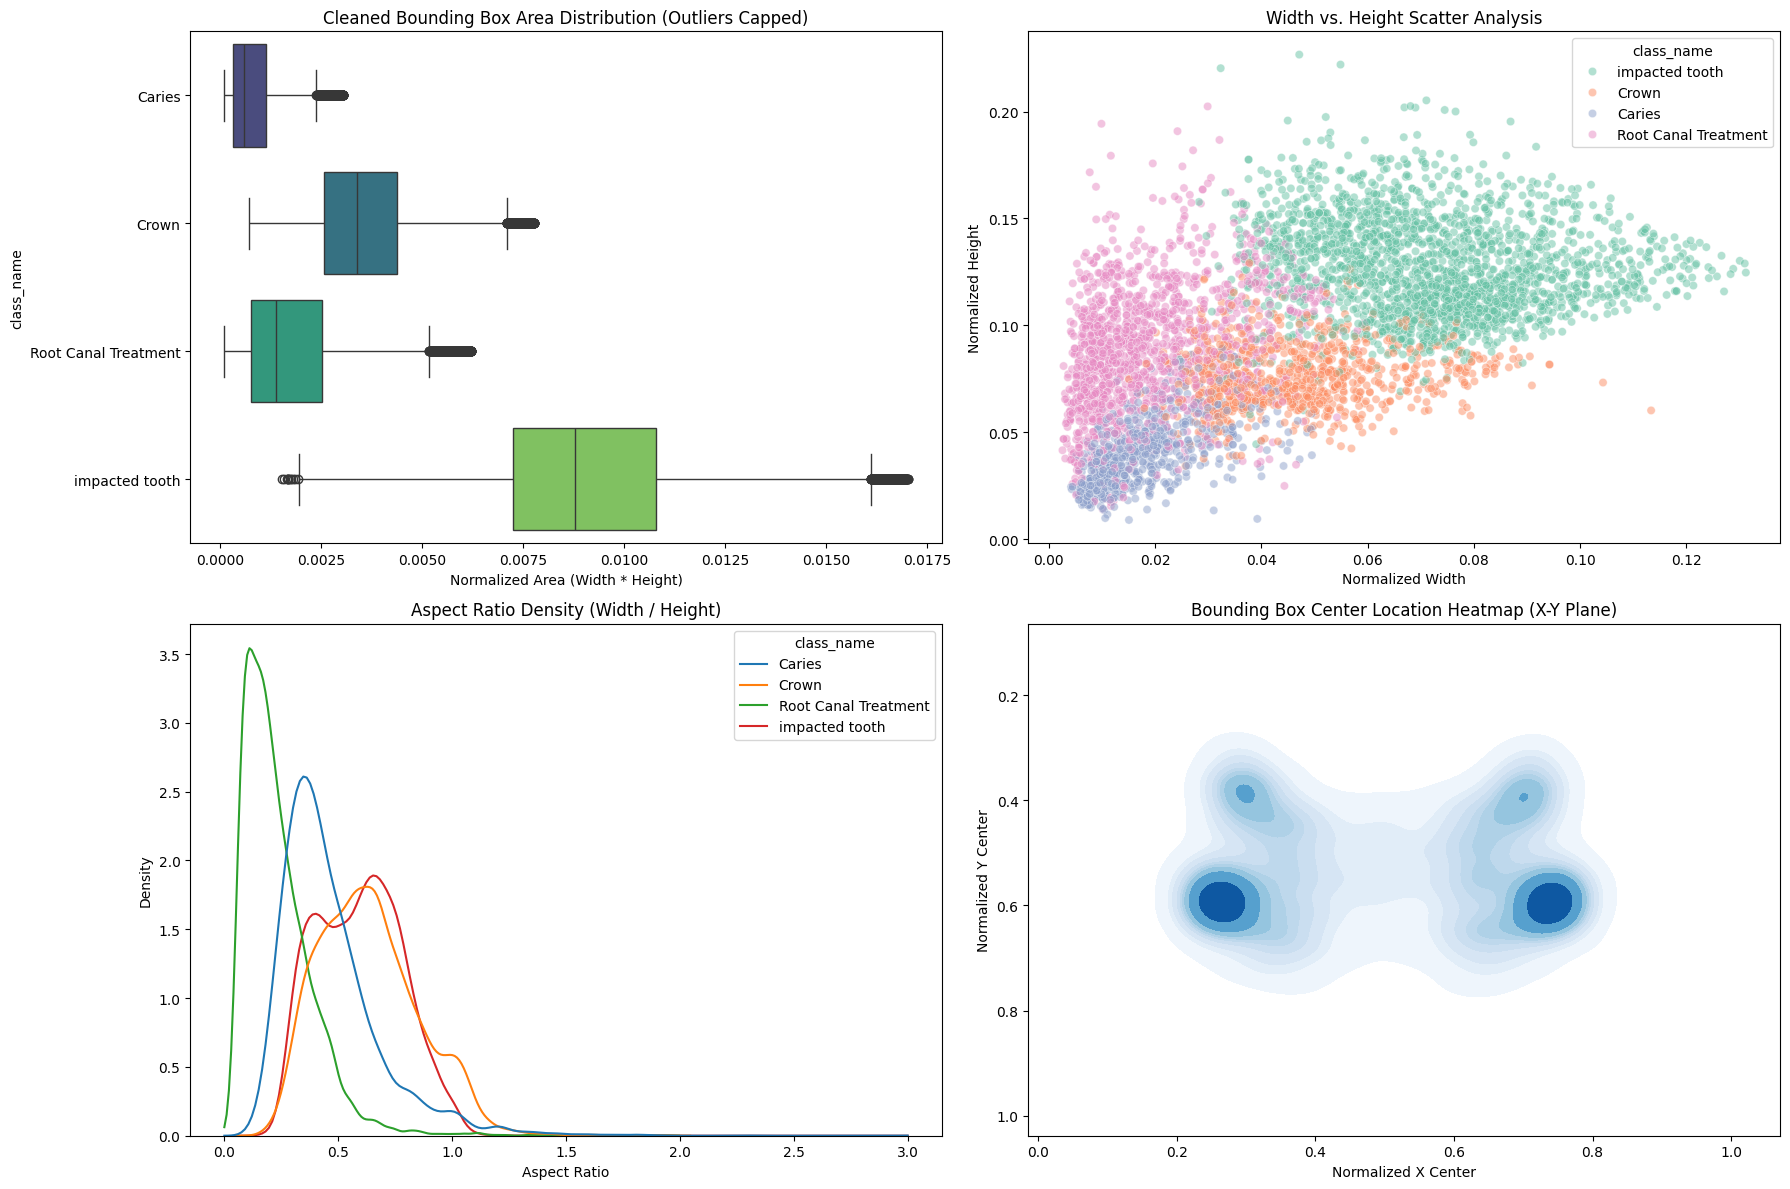


CLASS DIMENSION STATISTICAL SUMMARY
                      Mean_Width  Mean_Height  Mean_Area  Mean_Aspect_Ratio
class_name                                                                 
Caries                    0.0183       0.0406     0.0008             0.4650
Crown                     0.0471       0.0761     0.0036             0.6363
Root Canal Treatment      0.0194       0.0883     0.0018             0.2335
impacted tooth            0.0728       0.1269     0.0092             0.5946


In [26]:
import glob
import os
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Load data configuration
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get('names', [])

# 2. Extract bounding box properties
records = []
for split in ['train', 'valid', 'test']:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    try:
                        cls_id = int(parts[0])
                        cx, cy = float(parts[1]), float(parts[2])
                        w, h = float(parts[3]), float(parts[4])

                        # Filter invalid zero/negative dimensions
                        if w > 0 and h > 0:
                            records.append({
                                'file_path': lbl_file,
                                'split': split,
                                'class_id': cls_id,
                                'class_name': class_names[cls_id],
                                'cx': cx,
                                'cy': cy,
                                'w': w,
                                'h': h,
                                'area': w * h,
                                'aspect_ratio': w / h
                            })
                    except (ValueError, IndexError):
                        continue

df = pd.DataFrame(records)

# 3. Cap / Remove Outliers via IQR Filtering per Class
def filter_class_outliers(group):
    # Calculate IQR for area
    q1 = group['area'].quantile(0.25)
    q3 = group['area'].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    lower_bound = max(0.0001, q1 - 1.5 * iqr) # Ensure positive area

    # Filter within bounds
    return group[(group['area'] >= lower_bound) & (group['area'] <= upper_bound)]

df_cleaned = df.groupby('class_name', group_keys=False).apply(filter_class_outliers)

print("=" * 60)
print(f"Original Bounding Boxes: {len(df)}")
print(f"Cleaned Bounding Boxes (Post-IQR Outlier Removal): {len(df_cleaned)}")
print(f"Removed Outliers: {len(df) - len(df_cleaned)} instances")
print("=" * 60)

# 4. Multi-Panel Comprehensive EDA Plotting
fig = plt.figure(figsize=(18, 12))

# Subplot 1: Cleaned Box Area Distribution
ax1 = plt.subplot(2, 2, 1)
sns.boxplot(
    data=df_cleaned,
    x='area',
    y='class_name',
    hue='class_name',
    legend=False,
    palette='viridis',
    ax=ax1
)
ax1.set_title('Cleaned Bounding Box Area Distribution (Outliers Capped)', fontsize=12)
ax1.set_xlabel('Normalized Area (Width * Height)')

# Subplot 2: Bounding Box Dimensions Scatter (Width vs. Height)
ax2 = plt.subplot(2, 2, 2)
sns.scatterplot(
    data=df_cleaned.sample(min(5000, len(df_cleaned))), # Sample for plotting speed
    x='w',
    y='h',
    hue='class_name',
    alpha=0.5,
    palette='Set2',
    ax=ax2
)
ax2.set_title('Width vs. Height Scatter Analysis', fontsize=12)
ax2.set_xlabel('Normalized Width')
ax2.set_ylabel('Normalized Height')

# Subplot 3: Aspect Ratio Distributions (w / h)
ax3 = plt.subplot(2, 2, 3)
sns.kdeplot(
    data=df_cleaned,
    x='aspect_ratio',
    hue='class_name',
    common_norm=False,
    palette='tab10',
    ax=ax3,
    clip=(0, 3)
)
ax3.set_title('Aspect Ratio Density (Width / Height)', fontsize=12)
ax3.set_xlabel('Aspect Ratio')

# Subplot 4: Spatial Center Heatmap (Center X vs Center Y)
ax4 = plt.subplot(2, 2, 4)
sns.kdeplot(
    data=df_cleaned,
    x='cx',
    y='cy',
    cmap='Blues',
    fill=True,
    thresh=0.05,
    ax=ax4
)
ax4.set_title('Bounding Box Center Location Heatmap (X-Y Plane)', fontsize=12)
ax4.set_xlabel('Normalized X Center')
ax4.set_ylabel('Normalized Y Center')
ax4.invert_yaxis() # Match image coordinate system (0,0 at top-left)

plt.tight_layout()
plt.show()

# Print Class Statistics Summary Table
print("\n" + "=" * 60)
print("CLASS DIMENSION STATISTICAL SUMMARY")
print("=" * 60)
stats_df = df_cleaned.groupby('class_name').agg(
    Mean_Width=('w', 'mean'),
    Mean_Height=('h', 'mean'),
    Mean_Area=('area', 'mean'),
    Mean_Aspect_Ratio=('aspect_ratio', 'mean')
).round(4)
print(stats_df)

In [27]:
import glob
import os
import random
import shutil

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Identify raw label files across the dataset that contain non-target classes
# (e.g., images that contain background structures but no target 4 classes)
target_class_ids = [0, 1, 2, 3] # Our 4 active classes in data.yaml

train_img_dir = f"{extract_dir}/train/images"
train_lbl_dir = f"{extract_dir}/train/labels"

# Find all image paths
all_train_imgs = glob.glob(f"{train_img_dir}/*.jpg") + glob.glob(f"{train_img_dir}/*.png")

# Identify empty label files (images with 0 target annotations)
background_candidates = []

for img_path in all_train_imgs:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(train_lbl_dir, f"{base_name}.txt")

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            content = f.read().strip()
        # If the file is completely empty (because previous class filtering removed all non-4 targets)
        if not content:
            background_candidates.append(img_path)

print(f"Total pure background image candidates found: {len(background_candidates)}")

# 2. Keep a recommended ~5-10% background ratio (~1,000-2,000 images) to avoid overwhelming positive signals
bg_sample_size = min(1500, len(background_candidates))
random.seed(42)
selected_bg_imgs = random.sample(background_candidates, bg_sample_size)

# Ensure empty .txt files exist for selected background images
for img_path in selected_bg_imgs:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    lbl_path = os.path.join(train_lbl_dir, f"{base_name}.txt")
    with open(lbl_path, 'w') as f:
        f.write("") # Write empty label file for YOLO negative sampling

print(f"✅ Successfully integrated {len(selected_bg_imgs)} background images into the training set!")

Total pure background image candidates found: 274
✅ Successfully integrated 274 background images into the training set!


In [28]:
import glob
import os
import shutil
import random

extract_dir = "/content/dental-x-ray-panoramic-2"
train_img_dir = f"{extract_dir}/train/images"
train_lbl_dir = f"{extract_dir}/train/labels"

# 1. Clean up any previously added '_bg' files to avoid duplicates
existing_bg_imgs = glob.glob(f"{train_img_dir}/*_bg.jpg") + glob.glob(f"{train_img_dir}/*_bg.png")
existing_bg_lbls = glob.glob(f"{train_lbl_dir}/*_bg.txt")

for f in existing_bg_imgs + existing_bg_lbls:
    if os.path.exists(f):
        os.remove(f)

print(f"🧹 Cleaned up {len(existing_bg_imgs)} previously added background files.")


🧹 Cleaned up 0 previously added background files.


In [29]:
import glob
import os
import shutil
import random

extract_dir = "/content/dental-x-ray-panoramic-2"
train_img_dir = f"{extract_dir}/train/images"
train_lbl_dir = f"{extract_dir}/train/labels"

# Find all image paths across all splits (train, valid, test, or raw extracted)
all_images = glob.glob(f"{extract_dir}/**/*.jpg", recursive=True) + \
             glob.glob(f"{extract_dir}/**/*.png", recursive=True)

background_pool = []

for img_path in all_images:
    # Skip images already sitting in train/images to avoid duplication loops
    base_name = os.path.splitext(os.path.basename(img_path))[0]

    # Locate corresponding label path
    # Check if this image has any target annotations
    lbl_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt').replace('.png', '.txt')

    has_target_annotation = False
    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            content = f.read().strip()
            if content:  # If label has lines, check if it contains target 0,1,2,3
                has_target_annotation = True

    if not has_target_annotation:
        background_pool.append(img_path)

# Deduplicate background images by filename
unique_bg_dict = {os.path.basename(p): p for p in background_pool}
unique_bg_list = list(unique_bg_dict.values())

print(f"Total potential background images found across dataset: {len(unique_bg_list)}")

# Select up to 2,000 background images
TARGET_BG_COUNT = min(2000, len(unique_bg_list))
random.seed(42)
selected_bg = random.sample(unique_bg_list, TARGET_BG_COUNT)

added_count = 0
for img_path in selected_bg:
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    dest_img_path = os.path.join(train_img_dir, f"{base_name}_bg.jpg")
    dest_lbl_path = os.path.join(train_lbl_dir, f"{base_name}_bg.txt")

    # Copy background image into train/images if not already there
    if not os.path.exists(dest_img_path):
        shutil.copy(img_path, dest_img_path)

    # Create empty label file to mark as negative sample in YOLO
    with open(dest_lbl_path, 'w') as f:
        f.write("")

    added_count += 1

print(f"✅ Successfully added {added_count} background negative images into '{train_img_dir}'!")

Total potential background images found across dataset: 382
✅ Successfully added 382 background negative images into '/content/dental-x-ray-panoramic-2/train/images'!


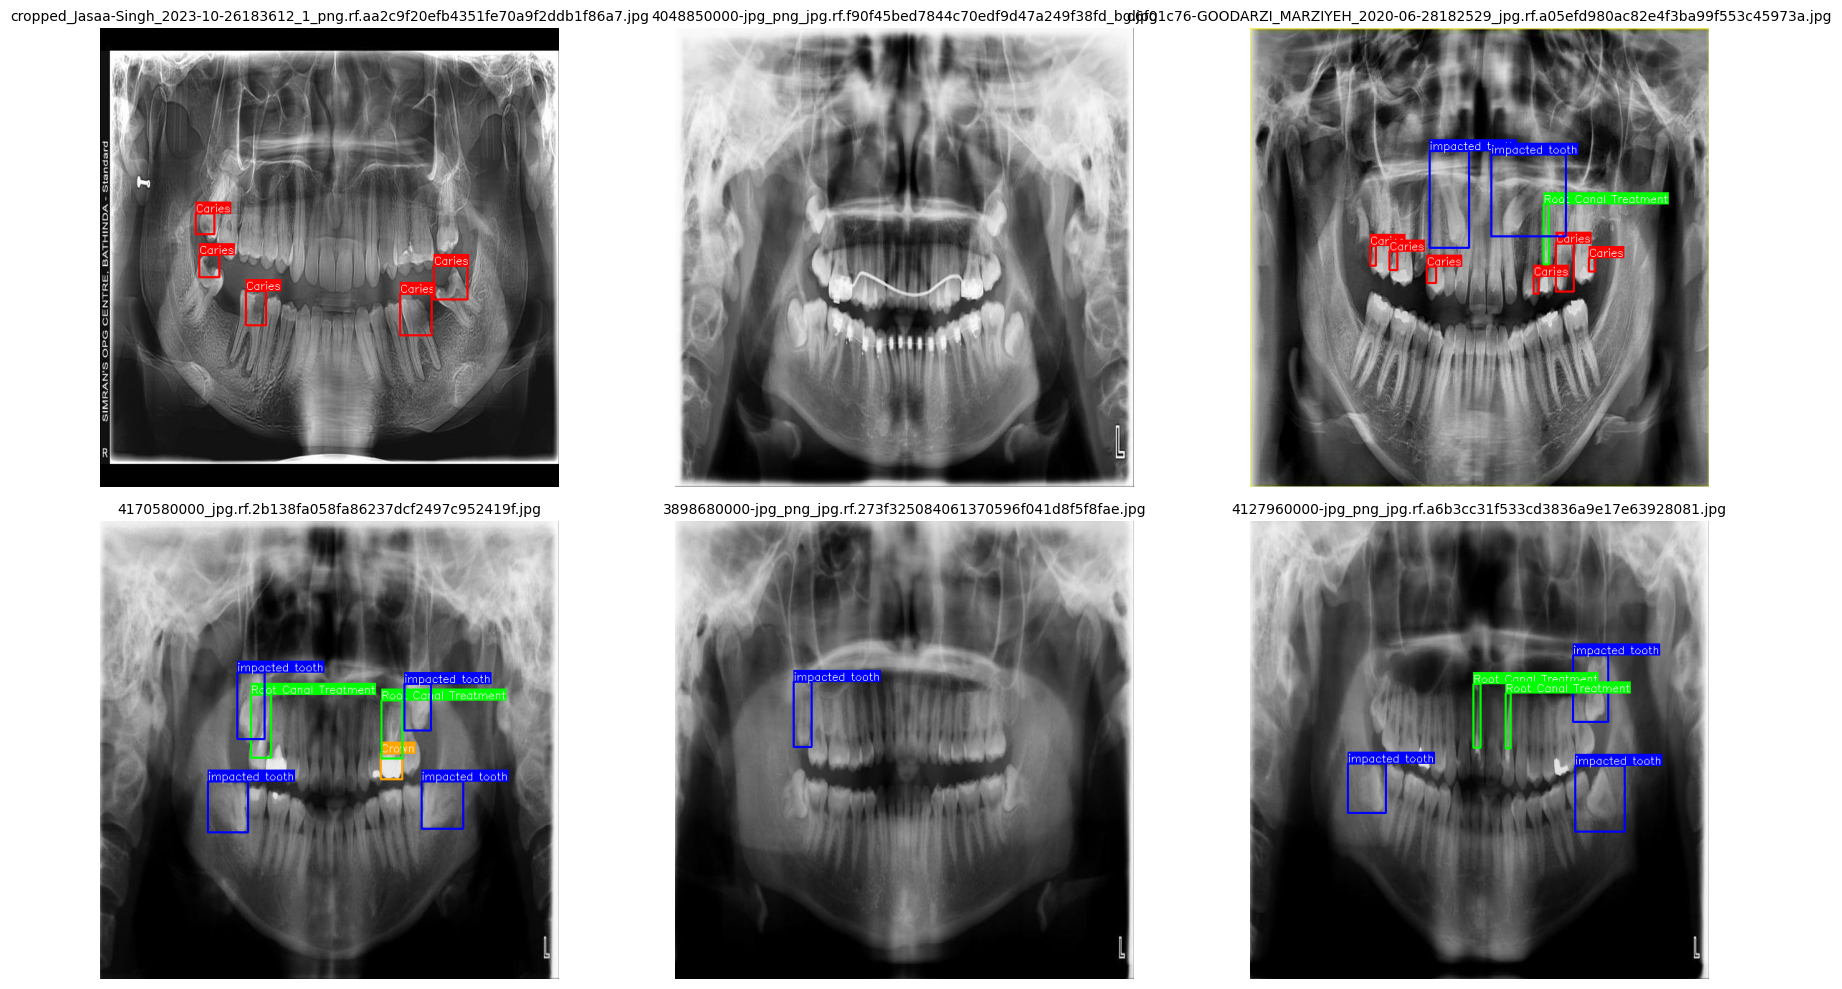

In [30]:
import glob
import os
import random
import cv2
import matplotlib.pyplot as plt

extract_dir = "/content/dental-x-ray-panoramic-2"
data_yaml_path = f"{extract_dir}/data.yaml"

# 1. Class mapping and bounding box color palette (BGR format for OpenCV)
CLASS_NAMES = ['impacted tooth', 'Root Canal Treatment', 'Crown', 'Caries']
CLASS_COLORS = {
    0: (255, 0, 0),     # Blue
    1: (0, 255, 0),     # Green
    2: (0, 165, 255),   # Orange
    3: (0, 0, 255)      # Red
}

def draw_yolo_annotations(img_path, lbl_path):
    """Loads image and draws bounding boxes with class labels."""
    img = cv2.imread(img_path)
    if img is None:
        return None

    img_h, img_w, _ = img.shape

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                cx, cy, w, h = map(float, parts[1:])

                # Convert normalized YOLO coordinates back to absolute pixel values
                xmin = int((cx - w / 2) * img_w)
                ymin = int((cy - h / 2) * img_h)
                xmax = int((cx + w / 2) * img_w)
                ymax = int((cy + h / 2) * img_h)

                # Bounding box color and label name
                color = CLASS_COLORS.get(cls_id, (255, 255, 255))
                label = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else str(cls_id)

                # Draw bounding box rectangle
                cv2.rectangle(img, (xmin, ymin), (xmax, ymax), color, 2)

                # Draw text label header
                text_size, _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
                text_w, text_h = text_size
                cv2.rectangle(img, (xmin, ymin - text_h - 4), (xmin + text_w, ymin), color, -1)
                cv2.putText(img, label, (xmin, ymin - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Select 6 random images across training set
train_img_dir = f"{extract_dir}/train/images"
image_files = glob.glob(f"{train_img_dir}/*.jpg") + glob.glob(f"{train_img_dir}/*.png")

random.seed(42)
sample_images = random.sample(image_files, min(6, len(image_files)))

# 3. Plot grid layout
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, img_path in enumerate(sample_images):
    lbl_path = img_path.replace('/images/', '/labels/').replace('.jpg', '.txt').replace('.png', '.txt')
    annotated_img = draw_yolo_annotations(img_path, lbl_path)

    if annotated_img is not None:
        axes[i].imshow(annotated_img)
        axes[i].set_title(os.path.basename(img_path), fontsize=10)
        axes[i].axis('off')

plt.tight_layout()
plt.show()

🔍 IMPACTED TOOTH REGION DISTRIBUTION ANALYSIS
Total 'impacted tooth' Annotations: 27600
Peripheral/Apical Zone (Likely Impacted): 3794 (13.7%)
Central Arch Zone (Suspicious Erupted Teeth): 23806 (86.3%)


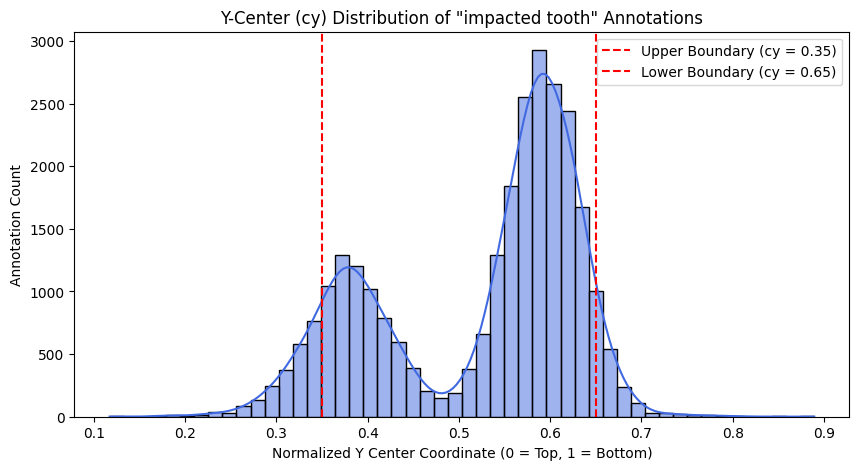

In [32]:
import glob
import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

extract_dir = "/content/dental-x-ray-panoramic-2"

# 1. Read class mapping
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    cfg = yaml.safe_load(f)

class_names = cfg.get('names', [])
impacted_idx = class_names.index('impacted tooth') if 'impacted tooth' in class_names else 0

# 2. Collect all 'impacted tooth' bounding box center coordinates
records = []
for split in ['train', 'valid', 'test']:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cls_id = int(parts[0])
                    if cls_id == impacted_idx:
                        cx, cy = float(parts[1]), float(parts[2])
                        w, h = float(parts[3]), float(parts[4])
                        records.append({
                            'split': split,
                            'cx': cx,
                            'cy': cy,
                            'w': w,
                            'h': h,
                            # Define central arch region vs peripheral bone region
                            'region': 'Central Arch (Suspicious Normal Erupted)' if 0.35 <= cy <= 0.65 else 'Apical/Basal Bone (Likely True Impacted)'
                        })

df_impacted = pd.DataFrame(records)

# 3. Print Statistical Breakdown
total_impacted = len(df_impacted)
suspicious_count = len(df_impacted[df_impacted['region'] == 'Central Arch (Suspicious Normal Erupted)'])
valid_count = total_impacted - suspicious_count

print("=" * 60)
print("🔍 IMPACTED TOOTH REGION DISTRIBUTION ANALYSIS")
print("=" * 60)
print(f"Total 'impacted tooth' Annotations: {total_impacted}")
print(f"Peripheral/Apical Zone (Likely Impacted): {valid_count} ({(valid_count/total_impacted)*100:.1f}%)")
print(f"Central Arch Zone (Suspicious Erupted Teeth): {suspicious_count} ({(suspicious_count/total_impacted)*100:.1f}%)")
print("=" * 60)

# 4. Plot Y-Axis Center Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_impacted['cy'], bins=50, kde=True, color='royalblue')
plt.axvline(0.35, color='red', linestyle='--', label='Upper Boundary (cy = 0.35)')
plt.axvline(0.65, color='red', linestyle='--', label='Lower Boundary (cy = 0.65)')
plt.title('Y-Center (cy) Distribution of "impacted tooth" Annotations')
plt.xlabel('Normalized Y Center Coordinate (0 = Top, 1 = Bottom)')
plt.ylabel('Annotation Count')
plt.legend()
plt.show()


In [34]:
import glob
import os
import yaml

extract_dir = "/content/dental-x-ray-panoramic-2"

# Load class mapping
yaml_path = f"{extract_dir}/data.yaml"
with open(yaml_path, 'r') as f:
    cfg = yaml.safe_load(f)

class_names = cfg.get('names', [])
impacted_idx = class_names.index('impacted tooth') if 'impacted tooth' in class_names else 0

removed_count = 0
kept_count = 0

for split in ['train', 'valid', 'test']:
    lbl_files = glob.glob(f"{extract_dir}/{split}/labels/*.txt")
    for lbl_file in lbl_files:
        with open(lbl_file, 'r') as f:
            lines = f.readlines()

        filtered_lines = []
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                cy = float(parts[2])

                # Filter out impacted tooth if in central arch (0.35 <= cy <= 0.65)
                if cls_id == impacted_idx and (0.35 <= cy <= 0.65):
                    removed_count += 1
                else:
                    filtered_lines.append(line.strip())
                    kept_count += 1

        with open(lbl_file, 'w') as f:
            f.write("\n".join(filtered_lines))

print(f"🧹 Purged {removed_count} suspicious 'impacted tooth' annotations from central arch.")
print(f"✅ Retained {kept_count} clean annotations across all classes.")

🧹 Purged 23806 suspicious 'impacted tooth' annotations from central arch.
✅ Retained 44217 clean annotations across all classes.
